# ACLS CO2 Group Project - Air Quality Prediction

## Problem Description

Urban air quality is strongly influenced by the interaction between traffic emissions and meteorological conditions. Pollutants such as nitrogen dioxide ([NO₂](https://www.stadt-zuerich.ch/de/gesundheit/gesundheitsschutz/luftqualitaet/luftschadstoffe/stickstoffdioxid.html)), ozone ([O₃](https://www.stadt-zuerich.ch/de/gesundheit/gesundheitsschutz/luftqualitaet/luftschadstoffe/ozon.html)), and particulate matter ([PM₁₀](https://www.stadt-zuerich.ch/de/gesundheit/gesundheitsschutz/luftqualitaet/luftschadstoffe/feinstaub.html)) show temporal variability driven by traffic intensity and weather-dependent dispersion processes. These relationships are often non-linear and vary across time scales.

Air pollution affects the health of humans, animals, and ecosystems, contributing to respiratory and cardiovascular diseases and environmental stress even at [relatively low concentrations](https://www.who.int/health-topics/air-pollution#tab=tab_1). Although [air quality in Zurich](https://www.stadt-zuerich.ch/content/dam/web/de/aktuell/publikationen/2025/luftbilanz-2024.pdf) has improved significantly over recent decades and largely complies with current regulatory limits, [guidelines by the World Health Organisation from 2021](https://iris.who.int/items/5b0ca7ab-830a-44b8-b99f-4ee743b4d7b2) recommend substantially lower threshold values. This highlights the need for more detailed analyses that go beyond simple limit-value exceedances.

According to the [Open Government Data](https://data.stadt-zuerich.ch/) guidelines, the city of Zurich provides long-term, high-resolution data on air pollutants, meteorology, and traffic. This is very advantageous for machine learning applications. Furthermore, these models are well suited to capture complex interactions and temporal patterns. By comparing different modelling approaches, our project aims to assess their performance and to better understand the relative importance of traffic and meteorological drivers under present-day air quality conditions.

For this project we decided to work with three air pollutants (NO₂, O₃, PM₁₀) as dependent variables and meteorological and traffic data as independent variables. We compare two linear regression models (Lasso and Ridge), a KNN regression model, and a tree-based model (Random Forest Regressor). We will also compare two different time-encodings (Trigonometric and Spline) to see which one performs better. For each model, we will perform feature importance analysis and hyperparameter tuning. Eventually, we will compare the performance of all models (ensemble voting) and select the best one for each pollutant.

## Libraries

In [72]:
import pandas as pd
import os
import missingno as msno

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import TimeSeriesSplit
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.model_selection import cross_validate
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
from scipy.stats import randint
from sklearn.ensemble import VotingRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, SplineTransformer

## Helper Functions

### Prepare Data

In [172]:
def read_files(file_paths: list, drop_columns: list, date_column: str, UTC=True):
    """
    Read multiple CSV files, clean them, parse datetime, and convert to UTC.

    This function:
    - Reads multiple CSV files and extracts the year from the file name.
    - Drops unwanted columns.
    - Combines all files into a single DataFrame.
    - Parses a datetime column and converts it to timezone-aware UTC.
    - Handles daylight saving time for traffic datasets (CET/CEST).
    - Renames the 'Standort' column to 'Location'.

    Args:
        file_paths (list): List of file paths to read.
        drop_columns (list): List of columns to drop from each CSV file.
        date_column (str): Name of the column containing datetime information.
        UTC (bool, optional): If True, treats the datetime column as fixed UTC+1 (air pollution data).
                              If False, treats it as CET/CEST (traffic data with DST). Default is True.

    Returns:
        pd.DataFrame: Combined and cleaned DataFrame with:
            - 'Year' column extracted from file names
            - 'Datetime' column as timezone-aware UTC
            - 'Location' column (renamed from 'Standort')
            - Original data columns minus dropped columns
    """

    # read in the files and set year in file name as new column
    dfs = [
        pd.read_csv(file, low_memory=False).assign(Year=int(file[-8:-4])).drop(columns=drop_columns)
        for file in file_paths
    ]

    # combine the files to one file
    df = pd.concat(dfs, ignore_index=True)

    # get correct data type for datetime column
    df['Datetime'] = pd.to_datetime(df[date_column])

    # in the air pollution data set the datetime column is in UTC+1 for the whole year
    # to make things easier, we convert it to UTC
    if UTC==True:
        df['Datetime'] = (df['Datetime']
                          .dt.tz_convert("UTC"))

    # the traffic data is in CET/CEST. therefore, we have to handle the missing and the duplicated hour at the end
    # of march and october, respectively (daylight saving time). this is done be the parameters in nonexistent and ambiguous.
    # to make things easier, we convert it to UTC as well.
    else:
        df['Datetime'] = (df['Datetime']
                          .dt.tz_localize("Europe/Zurich", nonexistent="shift_forward", ambiguous="infer")
                          .dt.tz_convert("UTC"))

    df = df.rename(columns={"Standort": "Location"})

    return df

In [188]:
def plot_average_week(df: pd.DataFrame, variable: str, y_label: str, title: str, ax):

    # Get the average number of vehicles per hour and weekday
    average_week = (
        df
        .groupby(["Weekday", "Hour", "Location"], as_index=False)[variable]
        .mean()
    )

    # Generate a column which shows the time of the week in hours
    average_week["time_of_week"] = average_week["Weekday"] * 24 + average_week["Hour"]

    sns.lineplot(
        data=average_week,
        x="time_of_week",
        y=variable,
        hue="Location",
        ax=ax
    )

    ax.set_xticks([i * 24 for i in range(7)])
    ax.set_xticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])

    ax.set_xlabel("Time of the Week")
    ax.set_ylabel(y_label)
    ax.set_title(title)

In [193]:
def plot_average_year(df: pd.DataFrame, variable: str, y_label: str, title: str, ax):

    # Get the average number of vehicles per hour and weekday
    average_year = (
        df
        .groupby(["Month", "Location"], as_index=False)[variable]
        .mean()
    )

    sns.lineplot(
        data=average_year,
        x="Month",
        #x_labels="Month_str",
        y=variable,
        hue="Location",
        ax=ax
    )

    ax.set_xlabel("Time of the Year")
    ax.set_ylabel(y_label)
    ax.set_title(title)

### Model Evaluation

In [74]:
# Model evaluation
def evaluate(model, X, y):
    ret = cross_validate(model, X, y, cv=tss, scoring=["neg_root_mean_squared_error"])
    rmse = -ret["test_neg_root_mean_squared_error"]
    print("%.2f ± %.2f" % (rmse.mean(), rmse.std()))

### Feature Importance

In [ ]:
# Build a grouping function
def group_features(feature_names):
    """
    Group feature names by their original variable base using the convention:
    e.g., 'scaled__T', 'Spline_time__Time_sp_3', etc.
    """
    groups = {}
    for f in feature_names:
        # original variable name = prefix before first underscore
        base = f.split("__")[1].split("_")[0]
        groups.setdefault(base, []).append(f)
    return groups


In [ ]:
# Compute grouped importance
def grouped_importance(model, X, y=None):
    # For Linear models
    if hasattr(model, "coef_"):
        raw = np.abs(model.coef_)
    # For Tree-based models
    elif hasattr(model, "feature_importances_"):
        raw = model.feature_importances_
    # Any other model without built-in importance
    else:
        if y is None:
            raise ValueError("y must be provided for models without built-in importance")
        # Sample from data, otherwise it is running very long
        X_sample = X.sample(5000, random_state=42)
        y_sample = y.loc[X_sample.index]
        permutation_result = permutation_importance(model, X_sample, y_sample, n_repeats=5, random_state=42)
        raw = permutation_result.importances_mean

    # Normalization
    normalized = raw / raw.sum()
    imp = pd.Series(normalized, index=X.columns)

    # Grouping
    groups = group_features(X.columns)
    grouped = {base: imp[cols].sum() for base, cols in groups.items()}

    return pd.Series(grouped).sort_values(ascending=False)

In [ ]:
# Make grouped plots
def plot_grouped_importance_multi(
    plots,
    model_name,
    feature_order=None,
    figsize=(18, 6),
    sharey=True
):
    """
    Plot multiple grouped feature-importance comparisons (Trig vs Spline)
    in a single figure.

    Parameters
    ----------
    plots : list of dict
        Each dict must contain:
        {
            "tri_imp": pd.Series,
            "spl_imp": pd.Series,
            "feature_name": str
        }
    model_name : str
        Name of the model (used in titles).
    feature_order : list of str, optional
        Desired order of grouped features.
    figsize : tuple
        Figure size.
    sharey : bool
        Share y-axis across subplots.
    """

    if feature_order is None:
        feature_order = [
            "Year", "Month", "Weekday", "Time", "Day",
            "Location",
            "Hr", "RainDur", "T", "WVv", "StrGlo",
            "meanVehicles"
        ]

    n = len(plots)
    fig, axes = plt.subplots(1, n, figsize=figsize, sharey=sharey)

    # Make axes iterable even if n == 1
    if n == 1:
        axes = [axes]

    for ax, p in zip(axes, plots):

        # Build grouped importance table
        df = pd.DataFrame({
            "Trig importance": p["tri_imp"],
            "Spline importance": p["spl_imp"]
        }).fillna(0)

        # Reorder and clean
        df = df.reindex(feature_order)
        df = df.dropna(how="all")

        if df.empty:
            ax.set_title(f'{p["feature_name"]} (no features)')
            ax.axis("off")
            continue

        df.plot(kind="bar", width=0.8, ax=ax)

        # Annotate bars
        for container in ax.containers:
            ax.bar_label(container, fmt="%.3f", padding=3, rotation=45, fontsize=6)

        ax.set_title(f'{model_name} - {p["feature_name"]}')
        ax.set_xlabel("Original Variable")
        ax.tick_params(axis="x", rotation=45)
        for tick in ax.get_xticklabels():
            tick.set_ha("right")

    axes[0].set_ylabel("Normalized Importance")
    fig.suptitle(f"{model_name} Feature Importance (Grouped)", y=1.02, fontsize=14)
    fig.tight_layout()
    plt.show()

In [ ]:
# Make grouped plots
def plot_grouped_importance(tri_imp, spl_imp, model_name, feature_name):
    """
    Plot grouped feature importance for trig vs spline models.
    tri_imp and spl_imp are the grouped importance Series.
    """
    df = pd.DataFrame({
        "Trig importance": tri_imp,
        "Spline importance": spl_imp
    }).fillna(0)

    # Reorder the features for visualisation
    feature_order = ["Year", "Month", "Weekday", "Time", "Day",
                     "Location",
                     "Hr", "RainDur", "T", "WVv", "StrGlo",
                     "meanVehicles"]

    df = df.reindex(feature_order)
    # Drop variables that are not present in this model (just in case of some pre-selection)
    df = df.dropna(how="all")

    plt.figure(figsize=(10, 6))
    ax = df.plot(kind="bar", width=0.8)
    # Add numeric labels on top of each bar
    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", padding=3, rotation=45, fontsize=6)

    plt.title(f"{model_name} Feature Importance (Grouped) – {feature_name}")
    plt.ylabel("Normalized Importance")
    plt.xlabel("Original Variable")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

In [ ]:
def get_importance_lda(model, feature_names, agg="l2"):
    """
    Per-feature importance from LDA coef_.
    Works for binary and multiclass by aggregating across class rows.

    Parameters
    ----------
    model : fitted sklearn.discriminant_analysis.LinearDiscriminantAnalysis
        Must expose coef_.
    feature_names : list-like
        Names in the same order used to fit the model.
    agg : {'l2','l1','max'}
        How to aggregate across classes when multiclass:
          - 'l2'  : Euclidean norm across classes (default, robust)
          - 'l1'  : Sum of absolute coefs across classes
          - 'max' : Max absolute coef across classes

    Returns
    -------
    pandas.Series
        Normalized importance per feature (sums to 1), sorted descending.
    """
    coef = np.asarray(model.coef_)
    if coef.ndim == 2 and coef.shape[0] > 1:
        if agg == "l1":
            imp = np.abs(coef).sum(axis=0)
        elif agg == "max":
            imp = np.abs(coef).max(axis=0)
        else:  # 'l2'
            imp = np.sqrt((coef ** 2).sum(axis=0))
    else:
        imp = np.abs(coef).ravel()

    imp = imp / (imp.sum() + 1e-12)

    if len(feature_names) != imp.shape[0]:
        raise ValueError(
            f"Feature length mismatch: {len(feature_names)} names vs {imp.shape[0]} coefficients."
        )

    return pd.Series(imp, index=feature_names).sort_values(ascending=False)


In [ ]:
def get_importance_lda_loadings(model, feature_names, agg="varweighted", k=None):
    """
    Importance from LDA discriminant loadings (solver='svd'):
      'absmean'     : mean |loading| across axes
      'absmax'      : max |loading| across axes
      'varweighted' : |loading| weighted by explained_variance_ratio_
    k: number of axes to aggregate (default: all)
    """
    if not hasattr(model, "scalings_"):
        raise ValueError("Use solver='svd' to get scalings_.")

    load = np.asarray(model.scalings_)  # (n_features, n_components)
    n_comp = load.shape[1]
    if k is None:
        k = n_comp
    L = np.abs(load[:, :k])

    if agg == "absmax":
        imp = L.max(axis=1)
    elif agg == "absmean":
        imp = L.mean(axis=1)
    else:  # varweighted
        w = getattr(model, "explained_variance_ratio_", None)
        if w is None:
            imp = L.mean(axis=1)
        else:
            w = np.asarray(w)[:k]
            w = w / (w.sum() + 1e-12)
            imp = (L * w).sum(axis=1)

    imp = imp / (imp.sum() + 1e-12)

    return pd.Series(imp, index = list(model.feature_names_in_)).sort_values(ascending=False)

In [75]:
def grouped_from_series(importance_series, X):
    groups = group_features(X.columns)
    grouped = {base: importance_series[cols].sum() for base, cols in groups.items()}
    return pd.Series(grouped).sort_values(ascending=False)

## Import and Preprocess Data

### Traffic Data

#### Read and Tidy Data

In [76]:
# This folder is not on GitHub, because it's too large
path = "data/traffic_h1/"

# Get the path of all files in the folder
files_traffic = os.listdir(path)

# Create full file paths
for i in range(len(files_traffic)):
    files_traffic[i] = os.path.join(path, files_traffic[i])

# Read and clean the traffic data. The read_files function handles the daylight saving time conversion (CET/CEST to UTC).
df_traffic_raw = read_files(file_paths=files_traffic, drop_columns=["MSID", "MSName", "ZSID", "Achse", "HNr", "Hoehe", "EKoord", "NKoord", "Knummer", "Kname", "AnzDetektoren", "D1ID", "D2ID", "D3ID", "D4ID", "LieferDat", "AnzFahrzeugeStatus"], date_column="MessungDatZeit", UTC=False)

In [77]:
# Create a map for the stations, that the stations of the traffic data can be merged with the stations of the air pollution and meteo data.
station_map = {
    "Rosengartenstrasse (Nordstrasse)": "Zch_Rosengartenstrasse",
    "Stampfenbachstrasse (Wasserwerkstrasse)": "Zch_Stampfenbachstrasse",
    "Schimmelstrasse (Werdstrasse)": "Zch_Schimmelstrasse"
}

In [78]:
# Check whether the stations in the traffic data are only those three stations we want to keep and combine.
df_traffic_raw = df_traffic_raw[df_traffic_raw["ZSName"].isin(station_map)]
df_traffic_raw["Location"] = df_traffic_raw["ZSName"].map(station_map)

# select the necessary columns only
df_traffic_raw = df_traffic_raw.loc[:, ["Richtung", "Year", "Datetime", "Location", "AnzFahrzeuge"]]
df_traffic_raw.head()

,Richtung,Year,Datetime,Location,AnzFahrzeuge
614880,Bucheggplatz,2012,2011-12-31 23:00:00+00:00,Zch_Rosengartenstrasse,561.0
614881,Bucheggplatz,2012,2012-01-01 00:00:00+00:00,Zch_Rosengartenstrasse,1223.0
614882,Bucheggplatz,2012,2012-01-01 01:00:00+00:00,Zch_Rosengartenstrasse,989.0
614883,Bucheggplatz,2012,2012-01-01 02:00:00+00:00,Zch_Rosengartenstrasse,826.0
614884,Bucheggplatz,2012,2012-01-01 03:00:00+00:00,Zch_Rosengartenstrasse,823.0


The sensors measure the traffic in two directions. Therefore, there are two entries per location and datetime. This is indicated by the "Richtung" column. This will be tackled later in the notebook.

#### Check Datetime Column

In [79]:
# Time is checked in UTC. Therefore, no problem with daylight saving time.
df_traffic_raw["Date"] = pd.to_datetime(df_traffic_raw["Datetime"]).dt.date
df_traffic_raw["Hour"] = pd.to_datetime(df_traffic_raw["Datetime"]).dt.hour

# Check for missing hours per location and day
hour_counts = (
    df_traffic_raw
    .groupby(["Location", "Date"])
    .size()
    .rename("n_hours")
    .reset_index()
)

missing_hours = hour_counts[hour_counts['n_hours'] != 48]
missing_hours

,Location,Date,n_hours
0,Zch_Rosengartenstrasse,2011-12-31,2
5114,Zch_Rosengartenstrasse,2025-12-31,46
5115,Zch_Schimmelstrasse,2011-12-31,2
10229,Zch_Schimmelstrasse,2025-12-31,46
10230,Zch_Stampfenbachstrasse,2011-12-31,2
15344,Zch_Stampfenbachstrasse,2025-12-31,46


As we converted the CET/CEST datetime column to UTC, there are two data points on 31.12.2011 and 46 only on 31.12.2025. This is correct. We check for 48 hours instead of 24 because the traffic is measured in two directions (as mentioned above). Therefore, each station and datetime consists of two data points.

#### Separate Datetime Column

In [80]:
df_traffic_raw["Time"] = pd.to_datetime(df_traffic_raw["Datetime"]).dt.time
df_traffic_raw["Month"] = pd.to_datetime(df_traffic_raw["Datetime"]).dt.month
df_traffic_raw["Day"] = pd.to_datetime(df_traffic_raw["Datetime"]).dt.day
df_traffic_raw["Month_str"] = pd.to_datetime(df_traffic_raw["Datetime"]).dt.month_name().str[:3]
df_traffic_raw["Weekday"] = pd.to_datetime(df_traffic_raw["Datetime"]).dt.weekday
df_traffic_raw["Weekday_str"] = pd.to_datetime(df_traffic_raw["Datetime"]).dt.day_name().str[:3]
# This separation is for plotting.
df_traffic_raw["YearMonth"] = pd.to_datetime(df_traffic_raw["Year"].astype(str)
                                             + "-"
                                             + df_traffic_raw["Month"].astype(str))
df_traffic_raw.head()

,Richtung,Year,Datetime,Location,AnzFahrzeuge,Date,Hour,Time,Month,Day,Month_str,Weekday,Weekday_str,YearMonth
614880,Bucheggplatz,2012,2011-12-31 23:00:00+00:00,Zch_Rosengartenstrasse,561.0,2011-12-31,23,23:00:00,12,31,Dec,5,Sat,2012-12-01
614881,Bucheggplatz,2012,2012-01-01 00:00:00+00:00,Zch_Rosengartenstrasse,1223.0,2012-01-01,0,00:00:00,1,1,Jan,6,Sun,2012-01-01
614882,Bucheggplatz,2012,2012-01-01 01:00:00+00:00,Zch_Rosengartenstrasse,989.0,2012-01-01,1,01:00:00,1,1,Jan,6,Sun,2012-01-01
614883,Bucheggplatz,2012,2012-01-01 02:00:00+00:00,Zch_Rosengartenstrasse,826.0,2012-01-01,2,02:00:00,1,1,Jan,6,Sun,2012-01-01
614884,Bucheggplatz,2012,2012-01-01 03:00:00+00:00,Zch_Rosengartenstrasse,823.0,2012-01-01,3,03:00:00,1,1,Jan,6,Sun,2012-01-01


#### Check NaN Values

Now we check the hourly traffic data for NaN values.

In [81]:
(df_traffic_raw
    .assign(is_na=df_traffic_raw["AnzFahrzeuge"].isna())
    .groupby(["Year", "Location"], as_index=False)
    .agg(n_missing_AnzFhz=("is_na", "sum"),
        count_Datetime=("Datetime", "count"),
        count_AnzFhz=("AnzFahrzeuge", "count"))
    .assign(
        missing_AnzFhz_perc=lambda d: round((d.count_Datetime - (d.count_Datetime-d.n_missing_AnzFhz))/d.count_Datetime*100, 2)))

,Year,Location,n_missing_AnzFhz,count_Datetime,count_AnzFhz,missing_AnzFhz_perc
0,2012,Zch_Rosengartenstrasse,2671,17568,14897,15.20
1,2012,Zch_Schimmelstrasse,66,17568,17502,0.38
2,2012,Zch_Stampfenbachstrasse,72,17568,17496,0.41
3,2013,Zch_Rosengartenstrasse,5123,17520,12397,29.24
4,2013,Zch_Schimmelstrasse,16,17520,17504,0.09
5,2013,Zch_Stampfenbachstrasse,16,17520,17504,0.09
6,2014,Zch_Rosengartenstrasse,17520,17520,0,100.00
7,2014,Zch_Schimmelstrasse,14,17520,17506,0.08
8,2014,Zch_Stampfenbachstrasse,606,17520,16914,3.46
9,2015,Zch_Rosengartenstrasse,11767,17520,5753,67.16


There are some locations which miss a high number of traffic data. Problematic locations and years are:
- Rosengartenstrasse: 2012 - 2015
- Stampfenbachstrasse: 2016 and 2017

We visualise the missing values over time for these two locations and the corresponding years.

In [82]:
df_plot = (df_traffic_raw
.query("Location in ['Zch_Rosengartenstrasse', 'Zch_Stampfenbachstrasse']")
.query("Year in [2012, 2013, 2014, 2015, 2016, 2017]")
.groupby(["YearMonth", "Location"], as_index=False)
.agg(
        count_Datetime=("Datetime", "count"),
        count_AnzFhz=("AnzFahrzeuge", "count"))
.assign(
        count_missing_AnzFhz_perc=lambda d: round((d.count_Datetime - d.count_AnzFhz)/d.count_Datetime*100, 2)))

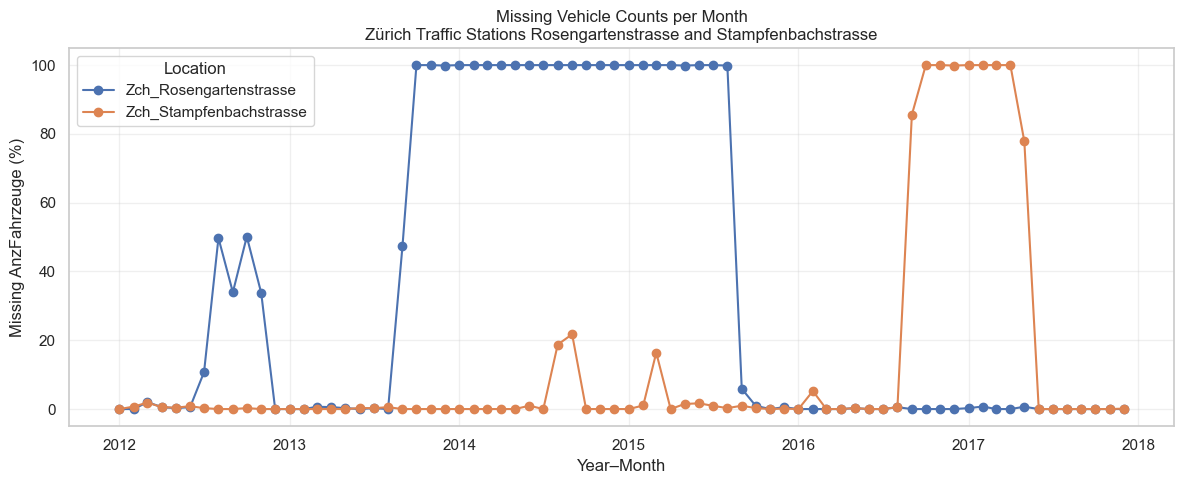

In [83]:
plt.figure(figsize=(12, 5))

for location, g in df_plot.groupby("Location"):
    plt.plot(
        g["YearMonth"],
        g["count_missing_AnzFhz_perc"],
        marker="o",
        label=location
    )

plt.ylabel("Missing AnzFahrzeuge (%)")
plt.xlabel("Year–Month")
plt.title("Missing Vehicle Counts per Month\nZürich Traffic Stations Rosengartenstrasse and Stampfenbachstrasse")

plt.legend(title="Location")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

We remove all NaNs and exclude years before 2018.

In [143]:
years = range(2018, 2026)

df_traffic_raw = df_traffic_raw[df_traffic_raw["Year"].isin(years)]
df_traffic = df_traffic_raw.dropna()
print("df_traffic 2018 - 2025 incl. NaNs shape:", df_traffic_raw.shape)
print("df_traffic 2018 - 2025 excl. NaNs shape:", df_traffic.shape)

df_traffic 2018 - 2025 incl. NaNs shape: (420768, 14)
df_traffic 2018 - 2025 excl. NaNs shape: (417976, 14)


#### Check Number of Data Points

For each location and datetime, there are two values for number of vehicles, because the sensor measures in both directions. To be sure, we check whether there are locations with more or less than two data points per datetime. The plan is to sum up the number of vehicles for the two directions.

In [85]:
direction_counts = (
    df_traffic
    .groupby(["Location", "Datetime"])
    .size()
    .rename("n_directions")
    .reset_index()
)

missing_direction = direction_counts[direction_counts['n_directions'] != 2]
missing_direction

,Location,Datetime,n_directions
4719,Zch_Rosengartenstrasse,2018-07-16 17:00:00+00:00,1
4720,Zch_Rosengartenstrasse,2018-07-16 18:00:00+00:00,1
4721,Zch_Rosengartenstrasse,2018-07-16 19:00:00+00:00,1
4722,Zch_Rosengartenstrasse,2018-07-16 20:00:00+00:00,1
4723,Zch_Rosengartenstrasse,2018-07-16 21:00:00+00:00,1
...,...,...,...
161977,Zch_Stampfenbachstrasse,2020-07-22 09:00:00+00:00,1
161978,Zch_Stampfenbachstrasse,2020-07-22 10:00:00+00:00,1
161979,Zch_Stampfenbachstrasse,2020-07-22 11:00:00+00:00,1
161980,Zch_Stampfenbachstrasse,2020-07-22 12:00:00+00:00,1


As there are nearly 1000 entries which miss the measurement of one lane / one direction (resulting in n_directions = 1), we rather calculate the average instead of the sum, so that we can keep these 992 data points.

In [144]:
df_traffic = (df_traffic.groupby(
    ["Year", "Location", "Datetime", "Date", "Time", "Hour", "Month", "Month_str", "Weekday", "Weekday_str", "Day", "YearMonth"], as_index=False)
              .agg(meanVehicles=("AnzFahrzeuge", "mean")))

print(df_traffic.shape)

(209484, 13)


#### Plot the Trend of Number of Vehicles

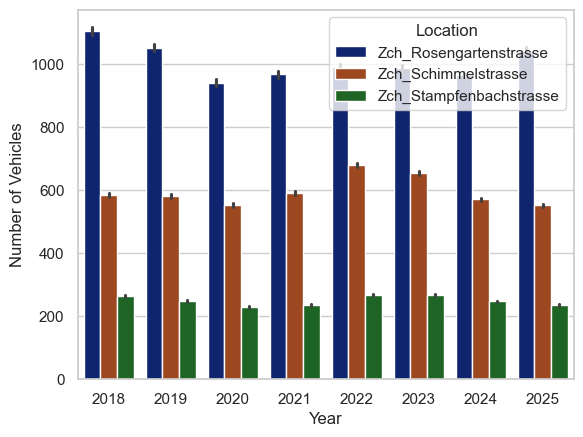

In [87]:
sns.set_theme(style="whitegrid")

# Draw a barplot by number of vehicles and location
g = sns.barplot(
    data=df_traffic,
    x="Year", y="meanVehicles", hue="Location",
    palette="dark", errorbar="ci"
).set(
    xlabel='Year',
    ylabel='Number of Vehicles'
)

The distribution of the tidied number of vehicles per year and location still looks reasonable. The location Rosengartenstrasse is stationed at a major traffic route, which explains the higher number of vehicles compared to the other two locations. The location Schimmelstrasse is still a busy street, but not as much as Rosengartenstrasse. The location Stampfenbachstrasse is located in a central area with less traffic, which explains the lower number of vehicles.

### Air Pollution Data

#### Read and Tidy Data

As we decided to start our analysis from 2018 onwards, we exclude the other years already.

In [88]:
path = "data/air_pollutants_h1/"

files_pollutants = os.listdir(path)

for i in range(len(files_pollutants)):
    files_pollutants[i] = os.path.join(path, files_pollutants[i])
df_pollutants = read_files(file_paths=files_pollutants, drop_columns=["Status", "Intervall"], date_column="Datum")

years = range(2018, 2026)

df_pollutants = df_pollutants[df_pollutants["Year"].isin(years)]

df_pollutants.head()

,Datum,Location,Parameter,Einheit,Wert,Year,Datetime
1044322,2018-01-01T00:00+0100,Zch_Heubeeribüel,NO2,µg/m3,3.94,2018,2017-12-31 23:00:00+00:00
1044323,2018-01-01T00:00+0100,Zch_Heubeeribüel,NO,µg/m3,1.20,2018,2017-12-31 23:00:00+00:00
1044324,2018-01-01T00:00+0100,Zch_Heubeeribüel,NOx,ppb,3.02,2018,2017-12-31 23:00:00+00:00
1044325,2018-01-01T00:00+0100,Zch_Heubeeribüel,O3,µg/m3,51.42,2018,2017-12-31 23:00:00+00:00
1044326,2018-01-01T00:00+0100,Zch_Rosengartenstrasse,NO2,µg/m3,17.20,2018,2017-12-31 23:00:00+00:00


Get an overview of the parameters and their units.

In [89]:
param_units_pollutants = (
    df_pollutants[["Parameter", "Einheit"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

param_units_pollutants

,Parameter,Einheit
0,NO2,µg/m3
1,NO,µg/m3
2,NOx,ppb
3,O3,µg/m3
4,PM10,µg/m3
5,PM2.5,µg/m3
6,CO,mg/m3
7,SO2,µg/m3


#### Create Pivot Table

The air pollution data is in long format. We pivot the table to get the pollutants as columns. Furthermore, we include the pollutants of interest only (NO2, O3, PM10).

In [90]:
# From long to wide format, so that each pollutant has its own column
df_pollutants_pivot = (
    df_pollutants
    .pivot(index=["Datetime", "Location", "Year"], columns="Parameter", values="Wert")
    .reset_index()
    .loc[:, ["Year", "Datetime", "Location", "NO2", "O3", "PM10"]]
)

# Remove multi-index
df_pollutants_pivot.columns.name = None

# Check shape of data frame
print("df_pollutants_pivot shape:", df_pollutants_pivot.shape)

# Check the end of the data frame
df_pollutants_pivot.tail()

df_pollutants_pivot shape: (280512, 6)


,Year,Datetime,Location,NO2,O3,PM10
280507,2025,2025-12-31 21:00:00+00:00,Zch_Stampfenbachstrasse,54.46,4.00,73.77
280508,2025,2025-12-31 22:00:00+00:00,Zch_Heubeeribüel,18.50,37.05,23.64
280509,2025,2025-12-31 22:00:00+00:00,Zch_Rosengartenstrasse,58.67,4.40,90.68
280510,2025,2025-12-31 22:00:00+00:00,Zch_Schimmelstrasse,60.34,1.94,89.89
280511,2025,2025-12-31 22:00:00+00:00,Zch_Stampfenbachstrasse,57.05,2.33,96.60


In [91]:
df_pollutants_pivot.describe()

,Year,NO2,O3,PM10
count,280512.000000,275856.000000,276367.000000,222888.000000
mean,2021.500342,24.447713,50.039260,14.420058
std,2.291143,17.346719,31.212433,9.451266
min,2018.000000,-0.070000,-0.830000,-9.850000
25%,2020.000000,10.420000,25.550000,8.140000
50%,2021.500000,20.800000,49.540000,12.510000
75%,2024.000000,34.800000,70.390000,18.360000
max,2025.000000,308.120000,196.510000,593.440000


The three pollutants show different ranges and distributions. O3 has the highest mean values. PM10 has the highest maximum values. The standard deviation is also highest for O3, indicating more variability in its concentrations compared to the other two pollutants.
There are also negative values for all of the pollutants, which are not physically meaningful. According to the research assistant of the city of Zurich, these negative values likely arise from measurement errors or calibration issues with the sensors. As the values are not too small and as proposed by the research assistant, we will keep these values.

#### Check Number of Data Points and NaN Values

In [92]:
(df_pollutants_pivot
.groupby(["Year", "Location"], as_index=False)
.agg(count_Datetime=("Datetime", "count"),
     count_NO2=("NO2", "count"),
     count_O3=("O3", "count"),
     count_PM10=("PM10", "count")))

,Year,Location,count_Datetime,count_NO2,count_O3,count_PM10
0,2018,Zch_Heubeeribüel,8760,8554,8696,0
1,2018,Zch_Rosengartenstrasse,8760,8607,8371,8663
2,2018,Zch_Schimmelstrasse,8760,8585,8568,8625
3,2018,Zch_Stampfenbachstrasse,8760,8709,8679,8663
4,2019,Zch_Heubeeribüel,8760,8632,8706,0
5,2019,Zch_Rosengartenstrasse,8760,8689,8642,8502
6,2019,Zch_Schimmelstrasse,8760,8623,8663,8712
7,2019,Zch_Stampfenbachstrasse,8760,8704,8721,8735
8,2020,Zch_Heubeeribüel,8784,8629,8612,0
9,2020,Zch_Rosengartenstrasse,8784,8717,8693,8702


It seems like measuring PM10 at Heubeeribüel started in 2024 only. As there are a lot of values missing for Heubeeribüel and we don't have any traffic data for this location, we will remove it. Unfortunately, Heubeeribüel is the only location in Zürich which represents a low-traffic area, which would have been interesting for our analysis.

In [93]:
df_pollutants_pivot = df_pollutants_pivot[df_pollutants_pivot["Location"] != "Zch_Heubeeribüel"]

#### Plot the Trend of Air Pollutants

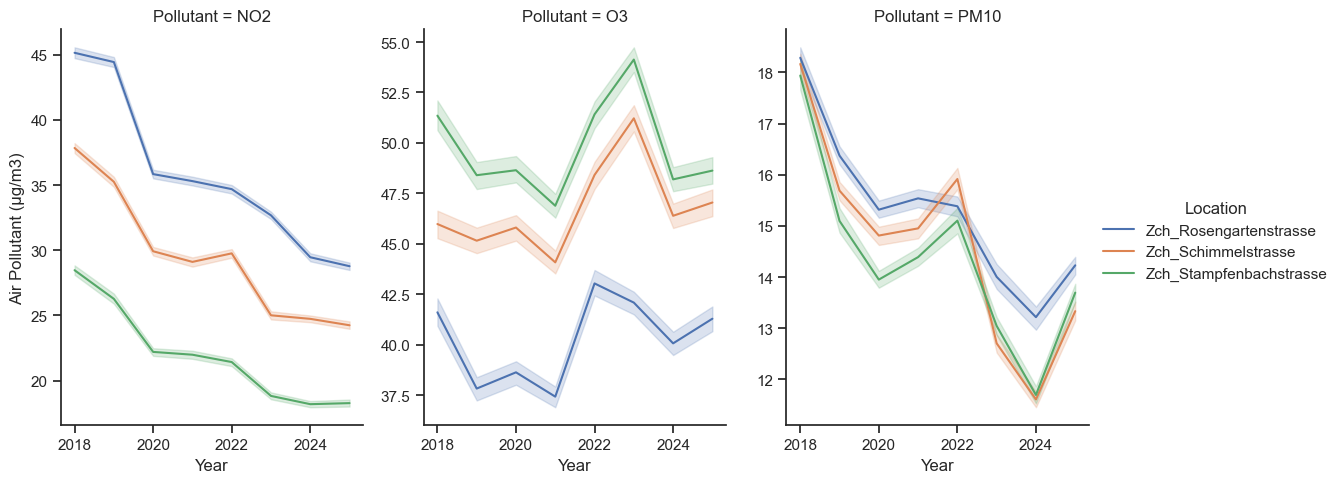

In [94]:
df_pollutants_plot = pd.melt(
    df_pollutants_pivot,
    id_vars=["Datetime", "Year", "Location"],
    value_vars=["NO2", "O3", "PM10"],
    var_name="Pollutant",
    value_name="Value"
)

sns.set_theme(style="ticks")

# Plot the lines on two facets
(sns.relplot(
    data=df_pollutants_plot,
    x="Year", y="Value",
    hue="Location", col="Pollutant",
    kind="line",
    height=5, aspect=.75, facet_kws={'sharey': False, 'sharex': True},
)
 .set_axis_labels("Year", "Air Pollutant (µg/m3)"))

The plots show the trends of the three pollutants over the years at different locations. NO2 levels appear to be decreasing slightly over time, which could indicate improvements in traffic emissions or air quality regulations. O3 levels seem relatively stable with minor fluctuations, while PM10 levels show more variability, possibly influenced by seasonal factors or specific pollution events.
NO2 and PM10 are highest at the location Rosengartenstrasse, which is expected due to its high traffic volume. O3 levels are more uniform across locations, as ozone is a secondary pollutant formed through photochemical reactions in the atmosphere. It gets broken down by nitogen oxide (NO + O3 -> NO2 + O2), which is emitted by traffic. Furthermore, chemical reaction producing O3 is highly influenced by sunlight (NO2 + O2 -sunlight-> NO + O3). Therefore, O3 levels are lower at high-traffic locations and higher at lower-traffic areas.

### Meteological Data

#### Read and Tidy Data

As the meteorological data is measured at the same locations as the air pollution data, the tidying process is similar. We again exclude years before 2018.

In [95]:
path = "data/ugz_meteo_h1/"

files_pollutants = os.listdir(path)

for i in range(len(files_pollutants)):
    files_pollutants[i] = os.path.join(path, files_pollutants[i])
df_meteo = read_files(file_paths=files_pollutants, drop_columns=["Status", "Intervall"], date_column="Datum")

years = range(2018, 2026)

df_meteo = df_meteo[df_meteo["Year"].isin(years)]

Get an overview of the parameters and their units.

In [96]:
param_units_meteo = (
    df_meteo[["Parameter", "Einheit"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

param_units_meteo

,Parameter,Einheit
0,Hr,%Hr
1,RainDur,min
2,T,°C
3,WD,°
4,WVv,m/s
5,p,hPa
6,StrGlo,W/m2
7,WVs,m/s


#### Create Pivot Table

In [97]:
df_meteo_pivot = (
    df_meteo
    .pivot(index=["Datetime", "Location", "Year"], columns="Parameter", values="Wert")
    .reset_index()
    .loc[:, ["Year", "Datetime", "Location", "Hr", "RainDur", "T", "WVv", "StrGlo"]]
)

df_meteo_pivot.columns.name = None

# remove Heubeeribüel
df_meteo_pivot = df_meteo_pivot[df_meteo_pivot["Location"] != "Zch_Heubeeribüel"]

# Check shape of data frame
print("df_meteo_pivot shape:", df_meteo_pivot.shape)

df_meteo_pivot.tail()

df_meteo_pivot shape: (210384, 8)


,Year,Datetime,Location,Hr,RainDur,T,WVv,StrGlo
227922,2025,2025-12-31 21:00:00+00:00,Zch_Schimmelstrasse,62.25,0.0,-2.36,0.38,NaN
227923,2025,2025-12-31 21:00:00+00:00,Zch_Stampfenbachstrasse,64.58,0.0,-2.63,1.11,0.01
227925,2025,2025-12-31 22:00:00+00:00,Zch_Rosengartenstrasse,71.02,0.0,-3.68,0.05,NaN
227926,2025,2025-12-31 22:00:00+00:00,Zch_Schimmelstrasse,64.54,0.0,-2.79,0.13,NaN
227927,2025,2025-12-31 22:00:00+00:00,Zch_Stampfenbachstrasse,66.82,0.0,-3.11,0.27,0.02


The variable "StrGlo" (radiation) is measured for the location Stampfenbachstrasse only. According to the research assistant of the City of Zurich which prepares the meteo and air pollution data, it is sensible to extrapolate the data measured at one location for the other location per datetime value. Therefore, we implement that.

In [98]:
df_meteo_pivot["StrGlo"] = (
    df_meteo_pivot.groupby("Datetime")["StrGlo"]
    .transform("first")
)
df_meteo_pivot.describe()

,Year,Hr,RainDur,T,WVv,StrGlo
count,210384.000000,205253.000000,208049.000000,207320.000000,206864.000000,210117.000000
mean,2021.500342,69.617717,4.814212,12.460484,0.793365,142.151315
std,2.291144,17.762133,13.969101,7.937261,0.914969,230.227800
min,2018.000000,12.700000,0.000000,-10.990000,0.000000,0.010000
25%,2020.000000,57.350000,0.000000,6.210000,0.200000,0.020000
50%,2021.500000,73.000000,0.000000,11.950000,0.440000,4.430000
75%,2024.000000,83.910000,0.000000,18.410000,1.050000,199.300000
max,2025.000000,101.370000,137.800000,36.380000,10.560000,1041.180000


#### Check Number of Data Points and NaN Values

In [99]:
df_meteo_pivot.isnull().sum()

Year           0
Datetime       0
Location       0
Hr          5131
RainDur     2335
T           3064
WVv         3520
StrGlo       267
dtype: int64

#### Plot the Trend of Meteo Data over the Years

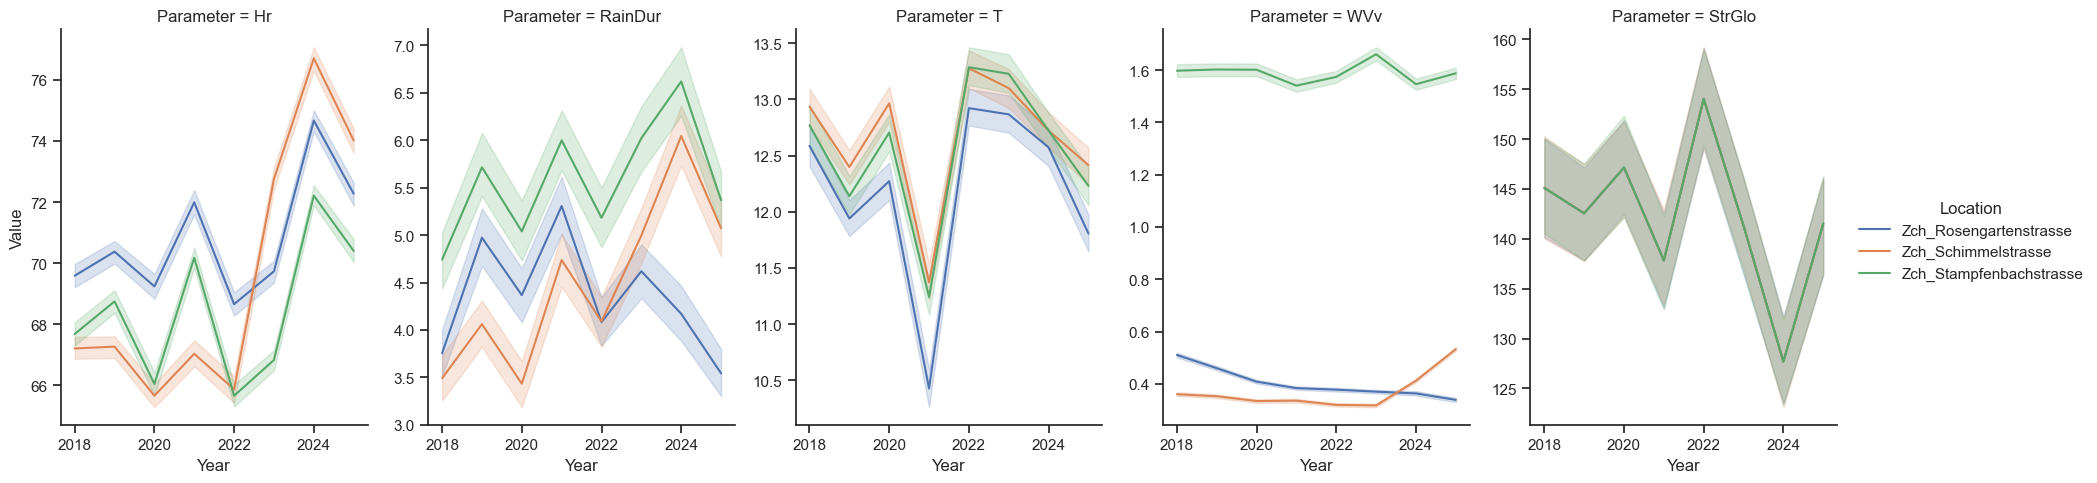

In [100]:
df_meteo_plot = pd.melt(
    df_meteo_pivot,
    id_vars=["Datetime", "Year", "Location"],
    value_vars=["Hr", "RainDur", "T", "WVv", "StrGlo"],
    var_name="Parameter",
    value_name="Value"
)

sns.set_theme(style="ticks")

# Plot the lines on two facets
sns.relplot(
    data=df_meteo_plot,
    x="Year", y="Value",
    hue="Location", col="Parameter",
    kind="line",
    height=5, aspect=.75, facet_kws={'sharey': False, 'sharex': True},
).set_axis_labels("Year", "Value")

### Merge Data Sets

#### Data Merging

In [156]:
# Combine all datasets across days and locations
df_combined = df_pollutants_pivot.merge(df_meteo_pivot, on=["Datetime", "Location"], how="outer") \
    .merge(df_traffic, on=["Datetime", "Location"], how="outer")

# remove the duplicated column "Year"
df_combined = df_combined.drop(columns=["Year_x", "Year_y"])

df_combined.tail()

,Datetime,Location,NO2,O3,PM10,Hr,RainDur,T,WVv,StrGlo,...,Date,Time,Hour,Month,Month_str,Weekday,Weekday_str,Day,YearMonth,meanVehicles
210379,2025-12-31 21:00:00+00:00,Zch_Schimmelstrasse,61.53,2.29,75.61,62.25,0.0,-2.36,0.38,0.01,...,2025-12-31,21:00:00,21.0,12.0,Dec,2.0,Wed,31.0,2025-12-01,472.5
210380,2025-12-31 21:00:00+00:00,Zch_Stampfenbachstrasse,54.46,4.00,73.77,64.58,0.0,-2.63,1.11,0.01,...,2025-12-31,21:00:00,21.0,12.0,Dec,2.0,Wed,31.0,2025-12-01,242.0
210381,2025-12-31 22:00:00+00:00,Zch_Rosengartenstrasse,58.67,4.40,90.68,71.02,0.0,-3.68,0.05,0.02,...,2025-12-31,22:00:00,22.0,12.0,Dec,2.0,Wed,31.0,2025-12-01,791.5
210382,2025-12-31 22:00:00+00:00,Zch_Schimmelstrasse,60.34,1.94,89.89,64.54,0.0,-2.79,0.13,0.02,...,2025-12-31,22:00:00,22.0,12.0,Dec,2.0,Wed,31.0,2025-12-01,518.0
210383,2025-12-31 22:00:00+00:00,Zch_Stampfenbachstrasse,57.05,2.33,96.60,66.82,0.0,-3.11,0.27,0.02,...,2025-12-31,22:00:00,22.0,12.0,Dec,2.0,Wed,31.0,2025-12-01,353.0


#### Check Correlation between Numeric Variables

For checking the correlation, we consider only the numeric variables:
- NO2: Nitrogen Dioxide concentration
- O3: Ozone concentration
- PM10: Particulate Matter concentration
- meanVehicles: Averaged number of vehicles (per lanes)
- Hr: Relative Humidity (%)
- RainDur: Rain Duration (min)
- T: Temperature (°C)
- WVv: Wind Velocity (m/s)

      - v stands for "vectorial". It indicates that the wind velocity is calculated considering both speed and direction. For example, if there is wind blowing from the north and afterwards from the south for the same time and speed, the vectorial wind velocity would be zero, as the two winds cancel each other out.
- StrGlo: Global Radiation (W/m²)

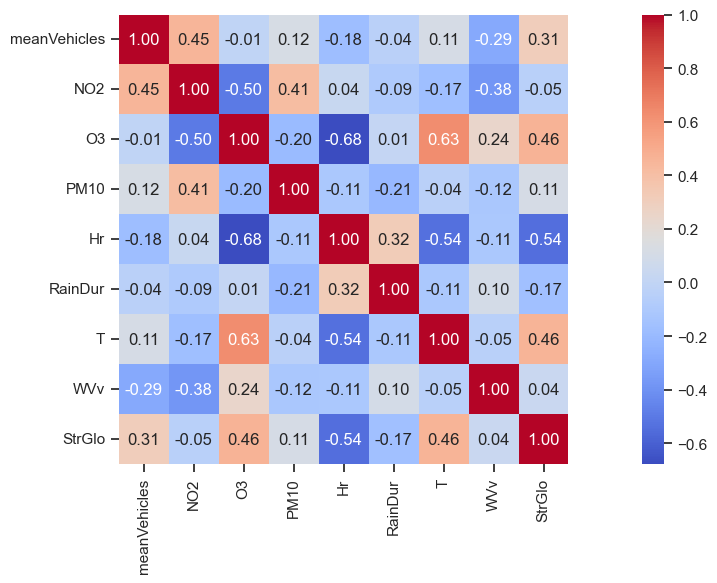

In [102]:
plt.figure(figsize=(15, 6))
sns.heatmap(
    df_combined[["meanVehicles", "NO2", "O3", "PM10", "Hr", "RainDur", "T", "WVv", "StrGlo"]].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    square=True
)
plt.tight_layout()
plt.show()

The averaged number of vehicles shows a moderate positive correlation with NO2 (0.45). This indicates that higher traffic volumes are associated with increased concentrations of NO2, which is expected due to vehicle emissions. The weak positive correlation with PM10 (0.12) is unexpected, as higher traffic leads to higher concentration of particles.
Conversely, there is almost no correlation between the averaged number of vehicles and O3 (-0.01). It would have been expected, that higher traffic volumes lead to lower O3 concentrations, as NO emitted by vehicles reacts with O3, breaking it down. However, O3 formation is complex and influenced by various factors, including sunlight and precursor emissions, which might explain the lack of correlation. Furthermore, O3 is positively correlated with temperature (0.63) and radiation (0.46), which indicates that photochemical reactions play a significant role in O3 formation.

#### Check Missing Values

In [103]:
df_combined.isnull().sum()

Datetime           0
Location           0
NO2             3479
O3              3416
PM10            5010
Hr              5131
RainDur         2335
T               3064
WVv             3520
StrGlo           267
Year             900
Date             900
Time             900
Month            900
Month_str        900
Weekday          900
Weekday_str      900
Day              900
YearMonth        900
meanVehicles     900
dtype: int64

<Axes: >

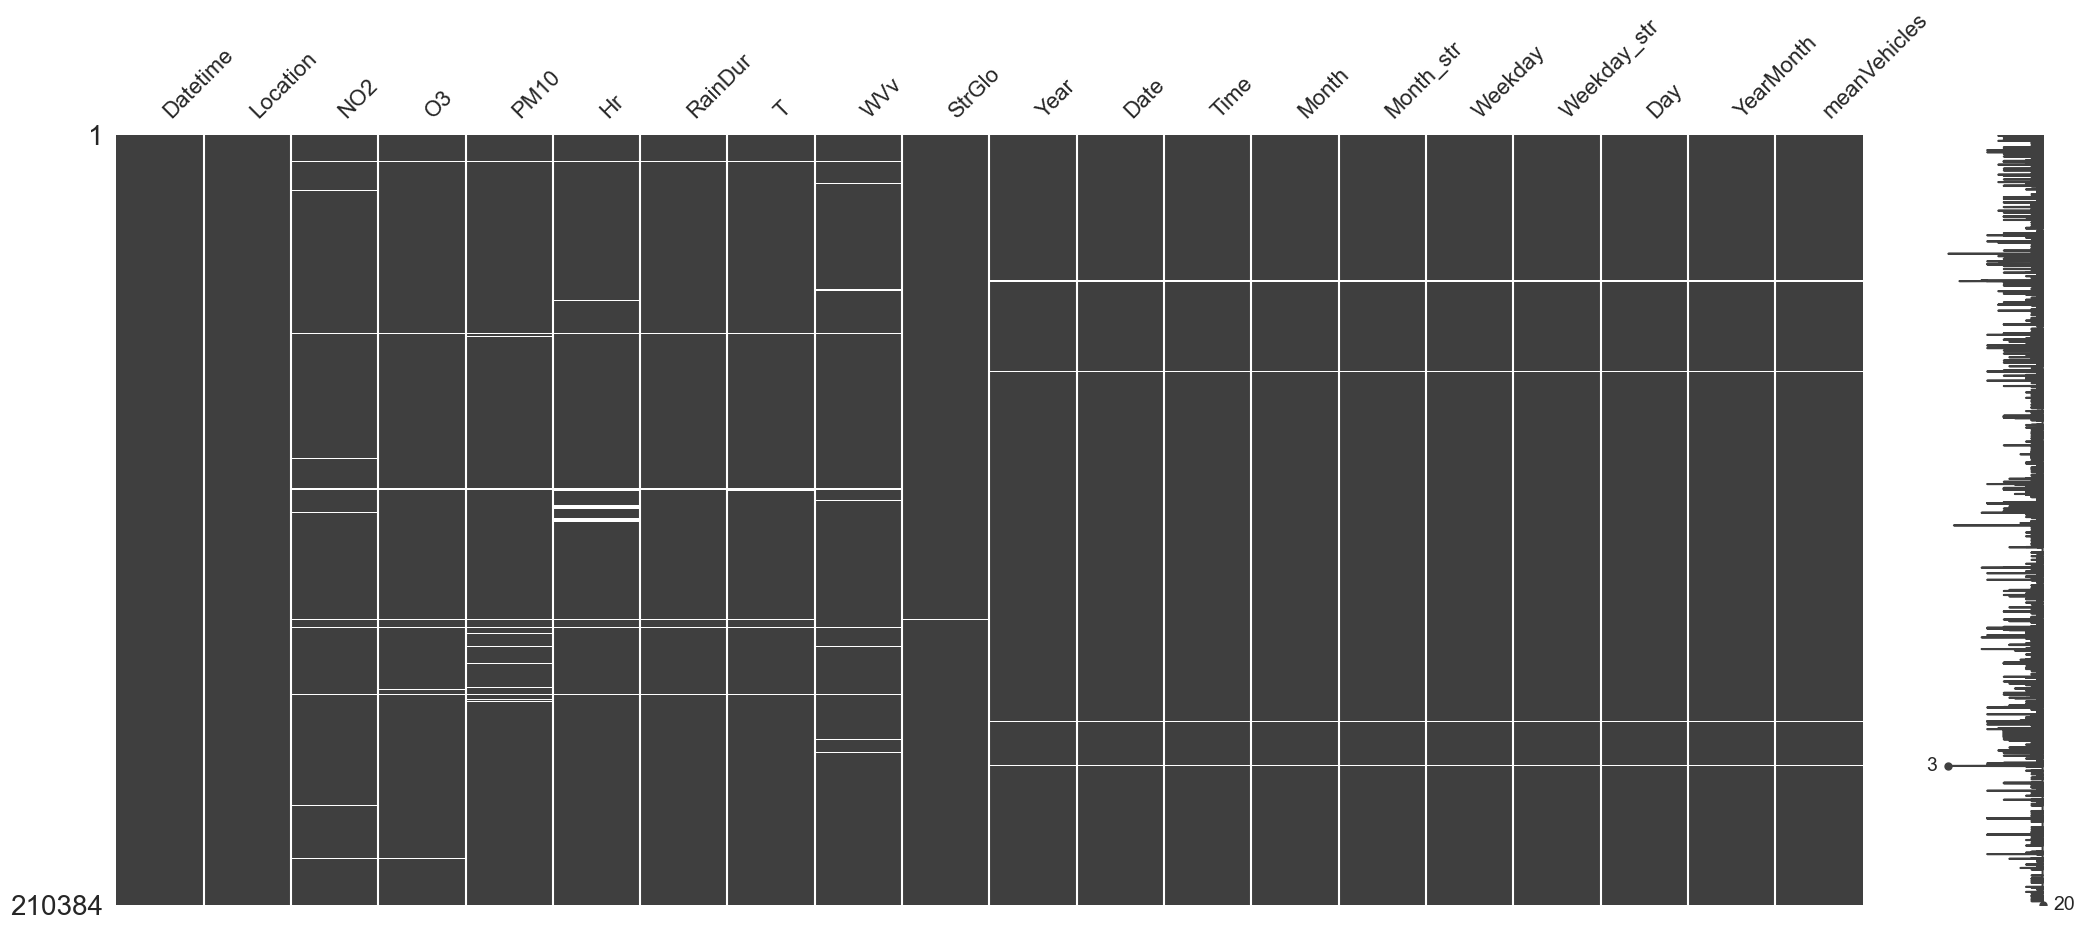

In [104]:
msno.matrix(df_combined)

The matrix of the missingno package visualises the missing values in the combined dataset. It is evident that there are a few missing values in the traffic data ("meanVehicles") for certain periods. The air pollution and meteorological data also show some missing values, but they are relatively sparse compared to the total amount of data points (which are represented in chronological order on the y-axis). Overall, the dataset appears to be reasonably complete for our analysis. Therefore, we will proceed with the available data without performing any imputation for the missing values, we will remove the rows with missing values instead.

In [158]:
df_combined_excl_nan = df_combined.dropna()

print("df_combined incl nan:", df_combined.shape)
print("df_combined excl nan:", df_combined_excl_nan.shape)

df_combined incl nan: (210384, 21)
df_combined excl nan: (197251, 21)


#### Plot Weekly Patterns

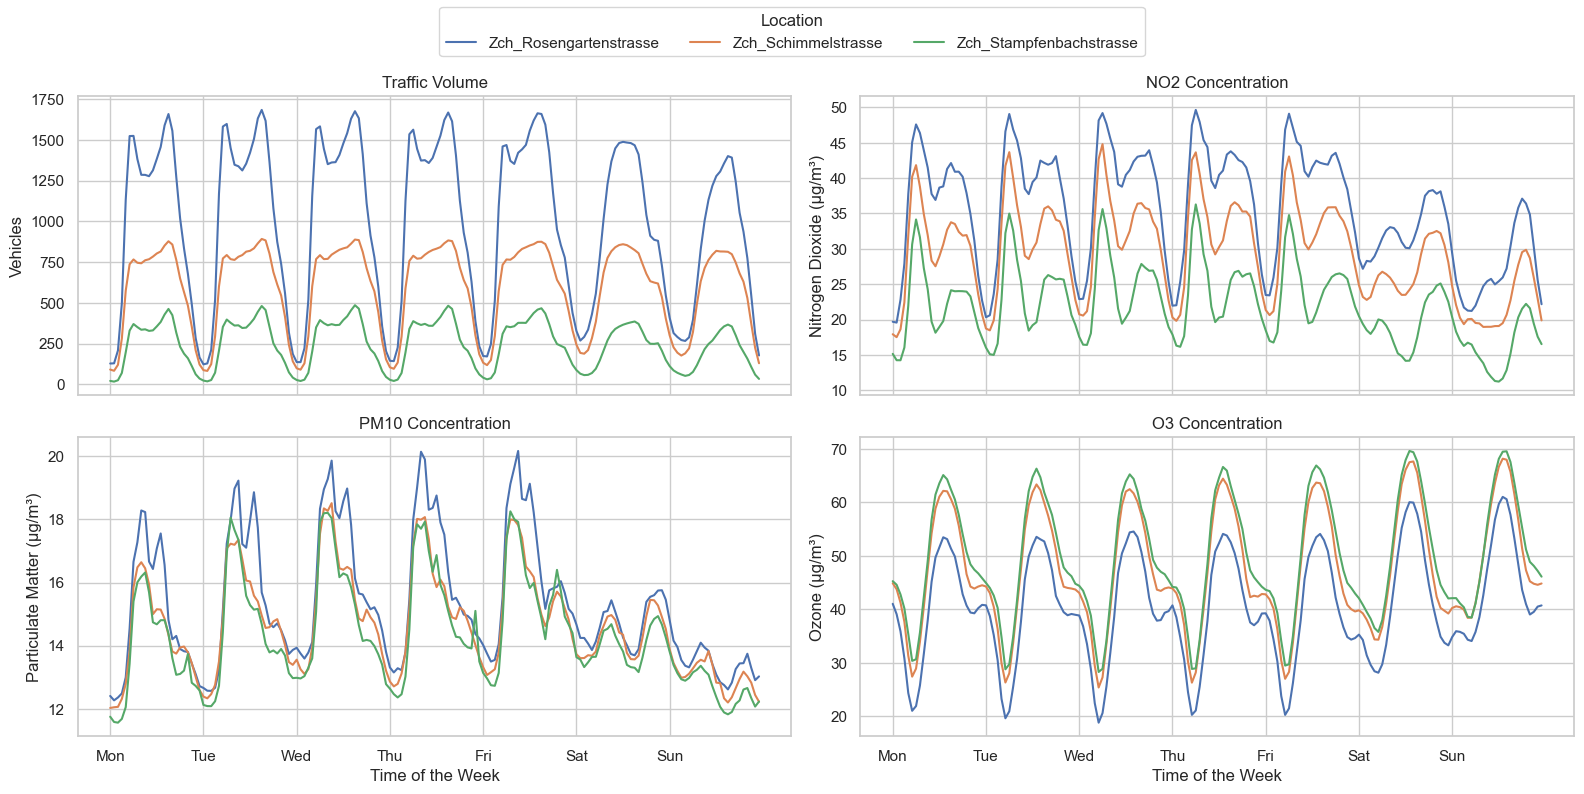

In [189]:
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 2, figsize=(16, 8), sharex=True)
axes = axes.flatten()

plot_average_week(df_combined_excl_nan, "meanVehicles", "Vehicles", "Traffic Volume", axes[0])
plot_average_week(df_combined_excl_nan, "NO2", "Nitrogen Dioxide (µg/m³)", "NO2 Concentration", axes[1])
plot_average_week(df_combined_excl_nan, "PM10", "Particulate Matter (µg/m³)", "PM10 Concentration", axes[2])
plot_average_week(df_combined_excl_nan, "O3", "Ozone (µg/m³)", "O3 Concentration", axes[3])

# Only one legend for all subplots
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Location", loc="upper center", ncol=len(labels))

# Remove individual legends
for ax in axes:
    ax.legend_.remove()

plt.tight_layout(rect=(0.0, 0.0, 1.0, 0.93))
plt.show()

The air pollutants NO2 and PM10 show clear weekly patterns, which are comparable with the traffic volume. Both pollutants have higher concentrations during weekdays, especially during rush hours in the morning and evening. This indicates that traffic emissions significantly contribute to the levels of these pollutants in the air. On weekends, when traffic volume is lower, the concentrations of NO2 and PM10 also decrease.
O3, on the other hand, exhibits a different pattern. Its concentration tends to be higher during weekends compared to weekdays. This is likely due to the reduced NO emissions from traffic, which allows O3 to accumulate in the atmosphere. Additionally, O3 levels peak during midday hours when sunlight is strongest, as sunlight drives the photochemical reactions that produce O3.
Overall, the weekly patterns of NO2 and PM10 closely follow the traffic volume, while O3 shows an inverse relationship with traffic patterns, highlighting the complex interactions between traffic emissions and air pollutant dynamics.

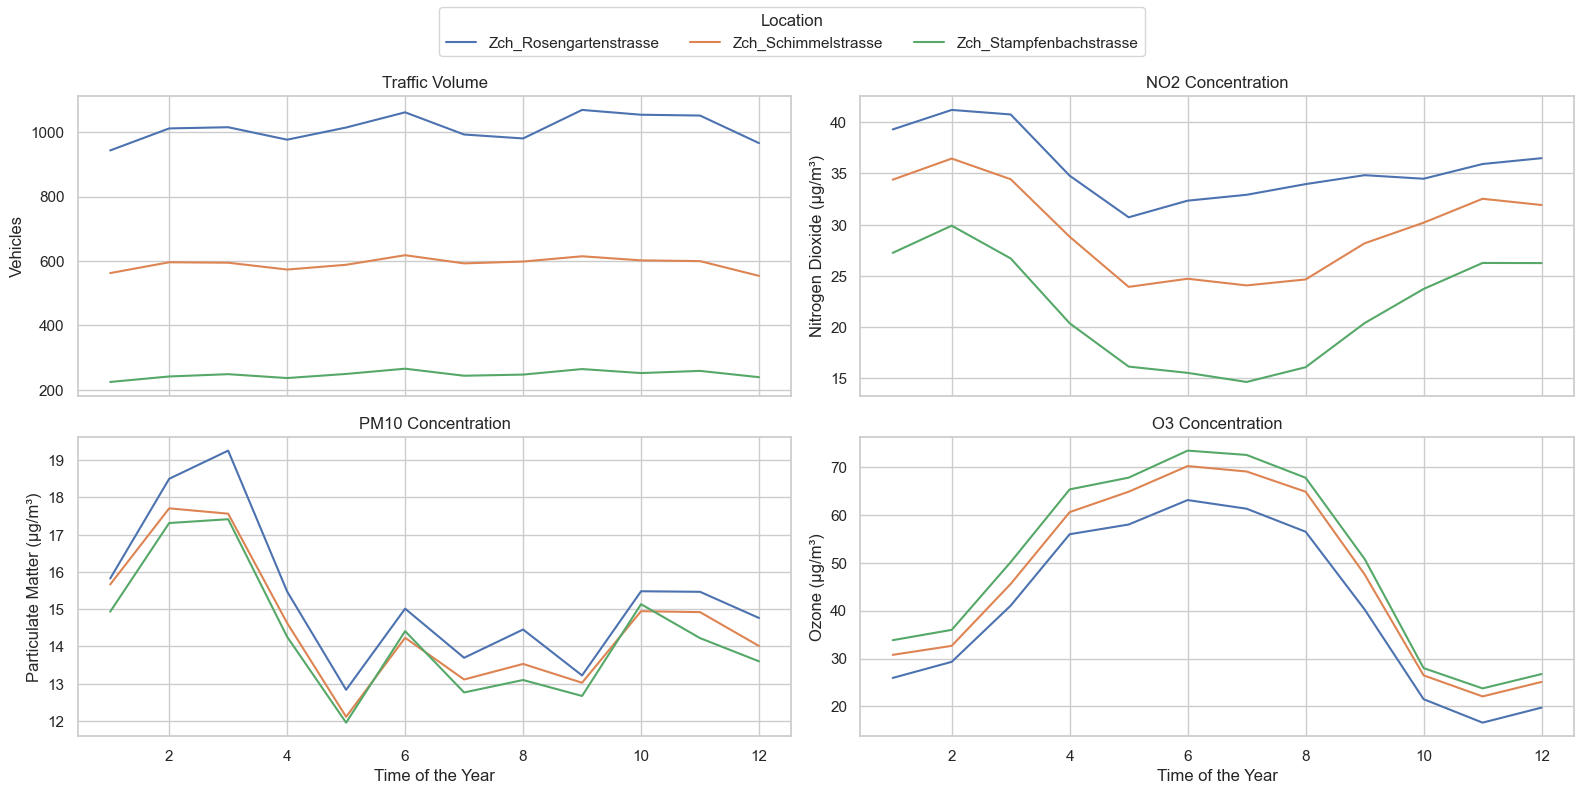

In [194]:
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 2, figsize=(16, 8), sharex=True)
axes = axes.flatten()

plot_average_year(df_combined_excl_nan, "meanVehicles", "Vehicles", "Traffic Volume", axes[0])
plot_average_year(df_combined_excl_nan, "NO2", "Nitrogen Dioxide (µg/m³)", "NO2 Concentration", axes[1])
plot_average_year(df_combined_excl_nan, "PM10", "Particulate Matter (µg/m³)", "PM10 Concentration", axes[2])
plot_average_year(df_combined_excl_nan, "O3", "Ozone (µg/m³)", "O3 Concentration", axes[3])

# Only one legend for all subplots
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Location", loc="upper center", ncol=len(labels))

# Remove individual legends
for ax in axes:
    ax.legend_.remove()

plt.tight_layout(rect=(0.0, 0.0, 1.0, 0.93))
plt.show()

Traffic volume is more or less constant during the year. NO2 and PM10 show increased values during the winter months (November to February) and lower values during the summer months (June to August). This seasonal pattern can be attributed to several factors. During winter, atmospheric conditions such as temperature inversions can trap pollutants close to the ground, leading to higher concentrations. Additionally, increased use of heating systems during colder months can contribute to elevated levels of these pollutants. In contrast, during summer, better atmospheric mixing and increased sunlight can enhance the dispersion and breakdown of pollutants, resulting in lower concentrations.
O3 exhibits an opposite seasonal trend compared to NO2 and PM10. O3 levels are higher during the summer months and lower during the winter months. This is primarily due to the fact that O3 is formed through photochemical reactions driven by sunlight. During summer, the longer daylight hours and stronger solar radiation facilitate the production of O3, leading to elevated levels. Conversely, in winter, the reduced sunlight and shorter days limit the formation of O3, resulting in lower concentrations.

## Prepare Data for Machine Learning

In this chapter we transform the combined dataset to be ready for machine learning models. First, we select the necessary columns and make sure that the time features are numbers and not strings. Then, we prepare a transformer which will be used to preprocess the data for the ML models. The locations will be one-hot encoded, the numeric variables will be standardised, and the time features will be encoded using both trigonometric encoding and periodic spline encoding. Finally, we split the data into training (2018 - 2024) and testing sets (2025) based on years.

In [106]:
df = df_combined_excl_nan.copy()

# Re-arrange columns
cols = ["Datetime", "YearMonth", "Date", "Year", "Month", "Month_str", "Weekday", "Weekday_str", "Day", "Time",
        "Location",
        "NO2", "O3", "PM10",
        "Hr", "RainDur", "T", "WVv", "StrGlo",
        "meanVehicles"]

df = df[cols]

In [107]:
# Select columns
cols_selected = ["Year", "Month", "Weekday", "Time", "Day",
                 "Location",
                 "NO2", "O3", "PM10",
                 "Hr", "RainDur", "T", "WVv", "StrGlo",
                 "meanVehicles"]

df_selected = df[cols_selected]

# Make sure the time features are numbers, not strings
df_ready = df_selected.copy()
df_ready["Time"] = pd.to_datetime(df_ready["Time"], format="%H:%M:%S").dt.hour.astype("int64")
df_ready["Month"] = df_selected["Month"].astype(int)
df_ready["Day"] = df_selected["Day"].astype(int)
df_ready["Weekday"] = df_selected["Weekday"].astype(int)

df_ready.head()

,Year,Month,Weekday,Time,Day,Location,NO2,O3,PM10,Hr,RainDur,T,WVv,StrGlo,meanVehicles
0,2018.0,12,6,23,31,Zch_Rosengartenstrasse,17.20,44.33,18.81,67.36,0.00,9.02,1.85,0.02,538.5
1,2018.0,12,6,23,31,Zch_Schimmelstrasse,9.33,49.89,16.57,64.18,0.00,9.60,0.70,0.02,340.0
2,2018.0,12,6,23,31,Zch_Stampfenbachstrasse,12.80,46.59,27.35,66.37,0.00,9.06,4.62,0.02,197.5
3,2018.0,1,0,0,1,Zch_Rosengartenstrasse,24.10,41.80,19.33,69.54,0.27,9.28,1.59,0.01,1029.0
4,2018.0,1,0,0,1,Zch_Schimmelstrasse,8.67,50.66,11.73,67.29,0.00,9.53,0.99,0.01,621.5


### Prepare transformer - to prepare data for ML models

In [108]:
# Preprocessing - OneHotEncoder, StandardScaler, Trigonometric encoding and SplineTransformer
# Prepare data transformer to be used in pipeline - do not use on the whole dataset!
# Encodings must be computed only on train data and then only applied on test data
# Trigonometric encoding could be in theory be done on the whole dataset, but for simplicity it is combined to have only one transformer

# Prepare Trigonometric encoding for time (safe before split)
def sin_transformer(period):
    return FunctionTransformer(lambda x: np.sin(x / period * 2 * np.pi))


def cos_transformer(period):
    return FunctionTransformer(lambda x: np.cos(x / period * 2 * np.pi))


# Prepare Spline Transformer
def periodic_spline_transformer(period, n_splines):
    degree = 3
    n_knots = n_splines + 1  # since include_bias is True
    return SplineTransformer(
        degree=degree,
        n_knots=n_knots,
        knots=np.linspace(0, period, n_knots).reshape(n_knots, 1),
        extrapolation="periodic",
        include_bias=True,
    )


# Prepare columns to be used
numeric_variables = ["Hr", "RainDur", "T", "WVv", "StrGlo", "meanVehicles"]

preprocess = ColumnTransformer(
    transformers=[
        ("Month_sin", sin_transformer(12), ["Month"]),
        ("Month_cos", cos_transformer(12), ["Month"]),
        ("Day_sin", sin_transformer(7), ["Day"]),
        ("Day_cos", cos_transformer(7), ["Day"]),
        ("Weekday_sin", sin_transformer(7), ["Weekday"]),
        ("Weekday_cos", cos_transformer(7), ["Weekday"]),
        ("Time_sin", sin_transformer(24), ["Time"]),
        ("Time_cos", cos_transformer(24), ["Time"]),
        ("Spline_month", periodic_spline_transformer(12, n_splines=5), ["Month"]),
        ("Spline_day", periodic_spline_transformer(7, n_splines=6), ["Day"]),
        ("Spline_weekday", periodic_spline_transformer(7, n_splines=6), ["Weekday"]),
        ("Spline_time", periodic_spline_transformer(24, n_splines=24), ["Time"]),
        ("encoded", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["Location"]),
        ("scaled", StandardScaler(), numeric_variables),
    ],
    remainder="passthrough"
).set_output(transform="pandas")

### Split for Train and Test - fit and transform the Preprocessing transformer

In [109]:
# Split manually based on year (to make sure the whole year is always included)
X_df = df_ready.drop(columns=["NO2", "O3", "PM10"]).copy()
y_df = df_ready[["NO2", "O3", "PM10"]].copy()

# Training datasets contain years 2018-2024
X_train = X_df[X_df["Year"].between(2018, 2024)].copy()
X_test = X_df[X_df["Year"] == 2025].copy()
# Testing datasets contain year 2025
y_train = y_df[X_df["Year"].between(2018, 2024)].copy()
y_test = y_df[X_df["Year"] == 2025].copy()

preprocess.fit(X_train)
X_train_transformed = preprocess.transform(X_train)
X_test_transformed = preprocess.transform(X_test)

### Target: Pollutants (continuous)

In [110]:
#df_train_y = pd.read_csv('data/Datasets_MLready/y_train.csv')
df_train_y = y_train.copy()
df_train_y.head()

,NO2,O3,PM10
0,17.20,44.33,18.81
1,9.33,49.89,16.57
2,12.80,46.59,27.35
3,24.10,41.80,19.33
4,8.67,50.66,11.73


In [111]:
#df_train_X = pd.read_csv('data/Datasets_MLready/X_train_transformed.csv')
df_train_X = X_train_transformed.copy()
df_train_X.head()

,Month_sin__Month,Month_cos__Month,Day_sin__Day,Day_cos__Day,Weekday_sin__Weekday,Weekday_cos__Weekday,Time_sin__Time,Time_cos__Time,Spline_month__Month_sp_0,Spline_month__Month_sp_1,...,encoded__Location_Zch_Rosengartenstrasse,encoded__Location_Zch_Schimmelstrasse,encoded__Location_Zch_Stampfenbachstrasse,scaled__Hr,scaled__RainDur,scaled__T,scaled__WVv,scaled__StrGlo,scaled__meanVehicles,remainder__Year
0,-2.449294e-16,1.000000,0.433884,-0.900969,-0.781831,0.62349,-0.258819,0.965926,0.166667,0.666667,...,1.0,0.0,0.0,-0.106724,-0.347905,-0.442934,1.127894,-0.617743,-0.145789,2018.0
1,-2.449294e-16,1.000000,0.433884,-0.900969,-0.781831,0.62349,-0.258819,0.965926,0.166667,0.666667,...,0.0,1.0,0.0,-0.286880,-0.347905,-0.369828,-0.105097,-0.617743,-0.563898,2018.0
2,-2.449294e-16,1.000000,0.433884,-0.900969,-0.781831,0.62349,-0.258819,0.965926,0.166667,0.666667,...,0.0,0.0,1.0,-0.162810,-0.347905,-0.437893,4.097794,-0.617743,-0.864052,2018.0
3,5.000000e-01,0.866025,0.781831,0.623490,0.000000,1.00000,0.000000,1.000000,0.033083,0.529225,...,1.0,0.0,0.0,0.016779,-0.328655,-0.410163,0.849131,-0.617786,0.887373,2018.0
4,5.000000e-01,0.866025,0.781831,0.623490,0.000000,1.00000,0.000000,1.000000,0.033083,0.529225,...,0.0,1.0,0.0,-0.110690,-0.347905,-0.378651,0.205832,-0.617786,0.029038,2018.0


In [112]:
# Select columns to create two separate datasets with different time-encodings (Trigonometric and Spline)
spline_cols = list(df_train_X.filter(like="Spline_").columns)
scaled_cols = list(df_train_X.filter(like="scaled_").columns)
encoded_cols = list(df_train_X.filter(like="encoded_").columns)
year_col = list(df_train_X.filter(like="remainder_").columns)
tri_cols = list(df_train_X.iloc[:,0:8].columns)

### Target: Locations (categorical)

In [113]:
df_train_y_Loc = pd.read_csv('data/Datasets_MLready_pred_Location/y_train_Loc.csv')
df_train_y_Loc.head()

,Location
0,Zch_Rosengartenstrasse
1,Zch_Schimmelstrasse
2,Zch_Stampfenbachstrasse
3,Zch_Rosengartenstrasse
4,Zch_Schimmelstrasse


In [114]:
df_train_X_Loc = pd.read_csv('data/Datasets_MLready_pred_Location/X_train_transformed_Loc.csv')
df_train_X_Loc.head()

,Month_sin__Month,Month_cos__Month,Day_sin__Day,Day_cos__Day,Weekday_sin__Weekday,Weekday_cos__Weekday,Time_sin__Time,Time_cos__Time,Spline_month__Month_sp_0,Spline_month__Month_sp_1,...,scaled__Hr,scaled__RainDur,scaled__T,scaled__WVv,scaled__StrGlo,scaled__meanVehicles,scaled__NO2,scaled__O3,scaled__PM10,remainder__Year
0,-2.449294e-16,1.000000,0.433884,-0.900969,-0.781831,0.62349,-0.258819,0.965926,0.166667,0.666667,...,-0.106724,-0.347905,-0.442934,1.127894,-0.617743,-0.145789,-0.712877,-0.054805,0.408815,2018.0
1,-2.449294e-16,1.000000,0.433884,-0.900969,-0.781831,0.62349,-0.258819,0.965926,0.166667,0.666667,...,-0.286880,-0.347905,-0.369828,-0.105097,-0.617743,-0.563898,-1.165838,0.129167,0.175959,2018.0
2,-2.449294e-16,1.000000,0.433884,-0.900969,-0.781831,0.62349,-0.258819,0.965926,0.166667,0.666667,...,-0.162810,-0.347905,-0.437893,4.097794,-0.617743,-0.864052,-0.966121,0.019975,1.296581,2018.0
3,5.000000e-01,0.866025,0.781831,0.623490,0.000000,1.00000,0.000000,1.000000,0.033083,0.529225,...,0.016779,-0.328655,-0.410163,0.849131,-0.617786,0.887373,-0.315745,-0.138519,0.462871,2018.0
4,5.000000e-01,0.866025,0.781831,0.623490,0.000000,1.00000,0.000000,1.000000,0.033083,0.529225,...,-0.110690,-0.347905,-0.378651,0.205832,-0.617786,0.029038,-1.203824,0.154645,-0.327177,2018.0


In [115]:
# Select columns to create two separate datasets with different time-encodings (Trigonometric and Spline)
spline_cols_Loc = list(df_train_X_Loc.filter(like="Spline_").columns)
scaled_cols_Loc = list(df_train_X_Loc.filter(like="scaled_").columns)
encoded_cols_Loc = list(df_train_X_Loc.filter(like="encoded_").columns)
year_col_Loc = list(df_train_X_Loc.filter(like="remainder_").columns)
tri_cols_Loc = list(df_train_X_Loc.iloc[:,0:8].columns)

## Machine Learning Models

### 3. Time-based cross-validation

In [116]:
# fixed training set size
tss = TimeSeriesSplit(n_splits=5,gap=24*2,max_train_size=24 * 365,test_size=24*30)

### 4. Model Evaluation

#### Target: Pollutants (continuous)

In [117]:
X_tri = df_train_X[encoded_cols + tri_cols + scaled_cols + year_col]
X_spl = df_train_X[encoded_cols + spline_cols + scaled_cols + year_col]

In [118]:
y_NO2 = df_train_y["NO2"]
y_O3 = df_train_y["O3"]
y_PM10 = df_train_y["PM10"]

In [119]:
df_train_y.describe()

,NO2,O3,PM10
count,171398.000000,171398.000000,171398.000000
mean,29.585936,45.986320,14.877335
std,17.374629,30.222047,9.619687
min,0.710000,-0.220000,-9.850000
25%,16.140000,21.350000,8.520000
50%,26.650000,44.960000,12.920000
75%,40.050000,66.140000,18.820000
max,308.120000,184.630000,593.440000


#### Target: Locations (continuous)

In [120]:
X_tri_Loc = df_train_X_Loc[encoded_cols_Loc + tri_cols_Loc + scaled_cols_Loc + year_col_Loc]
X_spl_Loc = df_train_X_Loc[encoded_cols_Loc + spline_cols_Loc + scaled_cols_Loc + year_col_Loc]

In [121]:
y_Location = df_train_y_Loc["Location"]

# Map station names -> class codes
loc_to_code = {
    'Zch_Rosengartenstrasse': 0,
    'Zch_Schimmelstrasse': 1,
    'Zch_Stampfenbachstrasse': 2
}

y_train_Location_codes = y_Location.map(loc_to_code).astype("int64")
#y_codes = pd.Series(y_Location).map(loc_to_code).astype("int64")

In [122]:
df_train_y_Loc.describe()
y_Location.describe()

count                      171398
unique                          3
top       Zch_Stampfenbachstrasse
freq                        59329
Name: Location, dtype: object

#### Base Model Multiple Linear Regression

In [123]:
# Building linear regression model
model_base = LinearRegression()

print("linear regression, trigonometric encoding, NO2")
evaluate(model_base, X_tri, y_NO2)

print("linear regression, spline encoding, NO2")
evaluate(model_base, X_spl, y_NO2)

print("linear regression, trigonometric encoding, O3")
evaluate(model_base, X_tri, y_O3)

print("linear regression, spline encoding, O3")
evaluate(model_base, X_spl, y_O3)

print("linear regression, trigonometric encoding, PM10")
evaluate(model_base, X_tri, y_PM10)

print("linear regression, spline encoding, PM10")
evaluate(model_base, X_spl, y_PM10)

linear regression, trigonometric encoding, NO2
11.16 ± 3.46
linear regression, spline encoding, NO2
12.04 ± 3.90
linear regression, trigonometric encoding, O3
19.19 ± 3.26
linear regression, spline encoding, O3
35.44 ± 34.50
linear regression, trigonometric encoding, PM10
6.73 ± 1.43
linear regression, spline encoding, PM10
11.68 ± 10.90


#### Model 2 - Lasso

In [124]:
# Build and evaluate a basic model
alpha = 0.1
model_lasso = Lasso(alpha=alpha)

print("Lasso, trigonometric encoding, NO2")
evaluate(model_lasso, X_tri, y_NO2)

print("Lasso, spline encoding, NO2")
evaluate(model_lasso, X_spl, y_NO2)

print("Lasso, trigonometric encoding, O3")
evaluate(model_lasso, X_tri, y_O3)

print("Lasso, spline encoding, O3")
evaluate(model_lasso, X_spl, y_O3)

print("Lasso, trigonometric encoding, PM10")
evaluate(model_lasso, X_tri, y_PM10)

print("Lasso, spline encoding, PM10")
evaluate(model_lasso, X_spl, y_PM10)

Lasso, trigonometric encoding, NO2
11.09 ± 3.55
Lasso, spline encoding, NO2
11.23 ± 3.41
Lasso, trigonometric encoding, O3
18.69 ± 3.38
Lasso, spline encoding, O3
18.29 ± 3.26
Lasso, trigonometric encoding, PM10
6.51 ± 0.73
Lasso, spline encoding, PM10
6.23 ± 0.33


#### Model 3 - Ridge

In [125]:
# Build and evaluate a basic model
alpha = 0.1
model_ridge = Ridge(alpha=alpha)

print("Ridge, trigonometric encoding, NO2")
evaluate(model_lasso, X_tri, y_NO2)

print("Ridge, spline encoding, NO2")
evaluate(model_lasso, X_spl, y_NO2)

print("Ridge, trigonometric encoding, O3")
evaluate(model_lasso, X_tri, y_O3)

print("Ridge, spline encoding, O3")
evaluate(model_lasso, X_spl, y_O3)

print("Ridge, trigonometric encoding, PM10")
evaluate(model_lasso, X_tri, y_PM10)

print("Ridge, spline encoding, PM10")
evaluate(model_lasso, X_spl, y_PM10)

Ridge, trigonometric encoding, NO2
11.09 ± 3.55
Ridge, spline encoding, NO2
11.23 ± 3.41
Ridge, trigonometric encoding, O3
18.69 ± 3.38
Ridge, spline encoding, O3
18.29 ± 3.26
Ridge, trigonometric encoding, PM10
6.51 ± 0.73
Ridge, spline encoding, PM10
6.23 ± 0.33


#### Model 4 - KNN Regression

In [126]:
# Build and evaluate a basic model
n_neighbors = 15
model_KNN = KNeighborsRegressor(n_neighbors, weights="uniform")

print("KNN, trigonometric encoding, NO2")
evaluate(model_lasso, X_tri, y_NO2)

print("KNN, spline encoding, NO2")
evaluate(model_lasso, X_spl, y_NO2)

print("KNN, trigonometric encoding, O3")
evaluate(model_lasso, X_tri, y_O3)

print("KNN, spline encoding, O3")
evaluate(model_lasso, X_spl, y_O3)

print("KNN, trigonometric encoding, PM10")
evaluate(model_lasso, X_tri, y_PM10)

print("KNN, spline encoding, PM10")
evaluate(model_lasso, X_spl, y_PM10)

KNN, trigonometric encoding, NO2
11.09 ± 3.55
KNN, spline encoding, NO2
11.23 ± 3.41
KNN, trigonometric encoding, O3
18.69 ± 3.38
KNN, spline encoding, O3
18.29 ± 3.26
KNN, trigonometric encoding, PM10
6.51 ± 0.73
KNN, spline encoding, PM10
6.23 ± 0.33


#### Model 6 - Random Forest Regressor

In [127]:
# Build and evaluate a random forest model

model_rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=5,
    max_samples=0.5,   # each tree sees 50% of rows
    n_jobs=-1,
    random_state=42
)

print("RF, trigonometric encoding, NO2")
evaluate(model_rf, X_tri, y_NO2)

print("RF, spline encoding, NO2")
evaluate(model_rf, X_spl, y_NO2)

print("RF, trigonometric encoding, O3")
evaluate(model_rf, X_tri, y_O3)

print("RF, spline encoding, O3")
evaluate(model_rf, X_spl, y_O3)

print("RF, trigonometric encoding, PM10")
evaluate(model_rf, X_tri, y_PM10)

print("RF, spline encoding, PM10")
evaluate(model_rf, X_spl, y_PM10)

RF, trigonometric encoding, NO2
10.33 ± 3.65
RF, spline encoding, NO2
10.44 ± 3.64
RF, trigonometric encoding, O3
17.58 ± 4.45
RF, spline encoding, O3
17.53 ± 4.48
RF, trigonometric encoding, PM10
7.15 ± 1.30
RF, spline encoding, PM10
7.14 ± 1.36


#### Model 7.1 - LDA 1D

In [128]:
# Build and evaluate a basic model
n_components = 1
model_LDA_1D = LDA(n_components=n_components, solver='svd')
X_train_lda = model_LDA_1D.fit_transform(X_tri_Loc, y_train_Location_codes)

print("LDA, trigonometric encoding, Location")
evaluate(model_LDA_1D, X_tri_Loc, y_train_Location_codes)
print("LDA, spline encoding, Location")
evaluate(model_LDA_1D, X_spl_Loc, y_train_Location_codes)

LDA, trigonometric encoding, Location
0.48 ± 0.05
LDA, spline encoding, Location
0.48 ± 0.06


#### Model 7.2 - LDA 2D

In [129]:
# Build and evaluate a basic model
n_components = 2
model_LDA_2D = LDA(n_components=n_components, solver='svd')
X_train_lda = model_LDA_2D.fit_transform(X_tri_Loc, y_train_Location_codes)

print("LDA, trigonometric encoding, Location")
evaluate(model_LDA_2D, X_tri_Loc, y_train_Location_codes)
print("LDA, spline encoding, Location")
evaluate(model_LDA_2D, X_spl_Loc, y_train_Location_codes)

LDA, trigonometric encoding, Location
0.48 ± 0.05
LDA, spline encoding, Location
0.48 ± 0.06


### 5. Feature selection

#### Model 2 - Lasso

In [130]:
# Train the models for the individual datasets
alpha = 0.1

lasso_tri_NO2 = Lasso(alpha=alpha).fit(X_tri, y_NO2)
lasso_spl_NO2 = Lasso(alpha=alpha).fit(X_spl, y_NO2)

lasso_tri_O3 = Lasso(alpha=alpha).fit(X_tri, y_O3)
lasso_spl_O3 = Lasso(alpha=alpha).fit(X_spl, y_O3)

lasso_tri_PM10 = Lasso(alpha=alpha).fit(X_tri, y_PM10)
lasso_spl_PM10 = Lasso(alpha=alpha).fit(X_spl, y_PM10)

# Build grouped importance tables for all 6 models
g_imp_lasso_tri_NO2 = grouped_importance(lasso_tri_NO2, X_tri)
g_imp_lasso_spl_NO2 = grouped_importance(lasso_spl_NO2, X_spl)

g_imp_lasso_tri_O3 = grouped_importance(lasso_tri_O3, X_tri)
g_imp_lasso_spl_O3 = grouped_importance(lasso_spl_O3, X_spl)

g_imp_lasso_tri_PM10 = grouped_importance(lasso_tri_PM10, X_tri)
g_imp_lasso_spl_PM10 = grouped_importance(lasso_spl_PM10, X_spl)

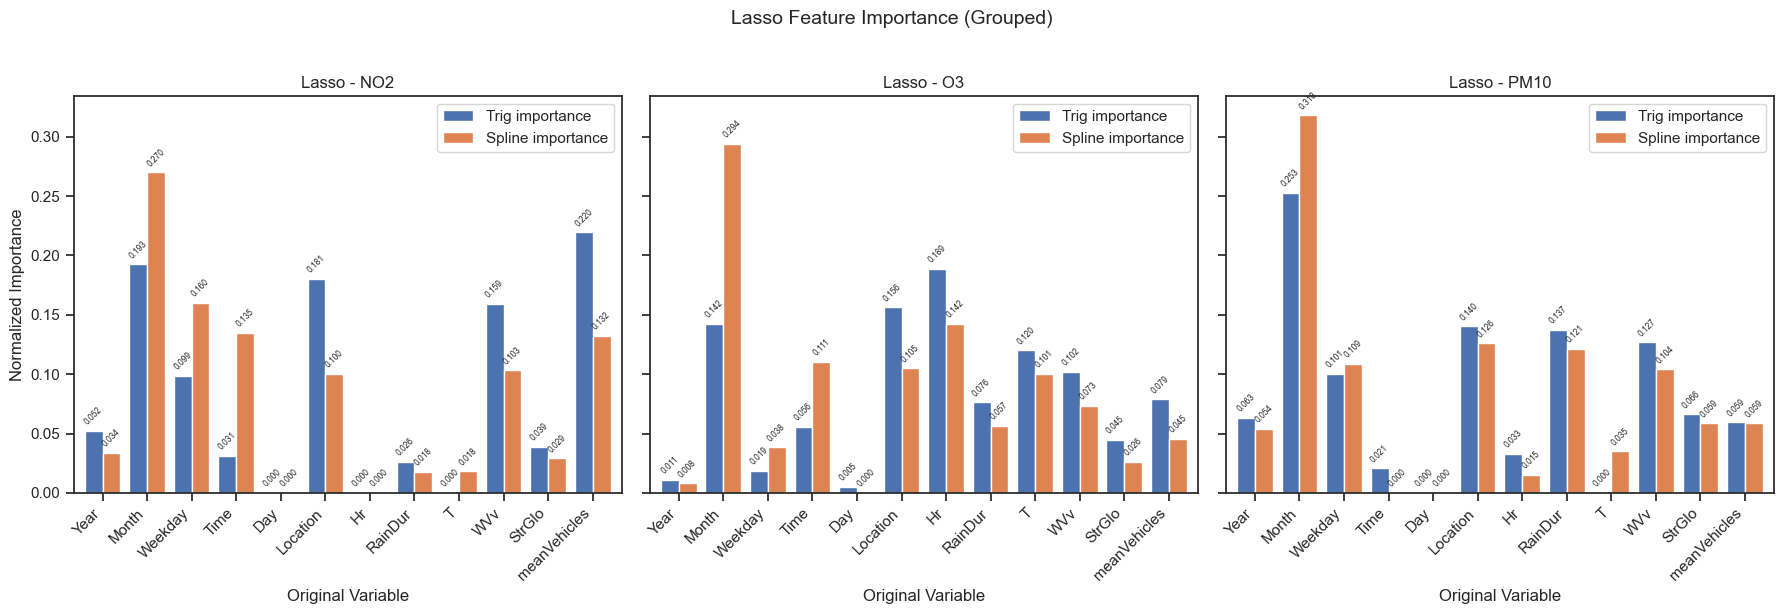

In [131]:
# Plot the grouped importance
plots = [
    {"tri_imp": g_imp_lasso_tri_NO2,  "spl_imp": g_imp_lasso_spl_NO2,  "feature_name": "NO2"},
    {"tri_imp": g_imp_lasso_tri_O3,   "spl_imp": g_imp_lasso_spl_O3,   "feature_name": "O3"},
    {"tri_imp": g_imp_lasso_tri_PM10, "spl_imp": g_imp_lasso_spl_PM10, "feature_name": "PM10"},
]

plot_grouped_importance_multi(
    plots,
    model_name="Lasso"
)

No weather or traffic feature is standing out as clearly not important for all 3 pollutants. For this reason, we keep all features in the dataset for the Lasso model

#### Model 3 - Ridge

In [132]:
# Train the models for the individual datasets
alpha = 0.1

ridge_tri_NO2 = Ridge(alpha=alpha).fit(X_tri, y_NO2)
ridge_spl_NO2 = Ridge(alpha=alpha).fit(X_spl, y_NO2)

ridge_tri_O3 = Ridge(alpha=alpha).fit(X_tri, y_O3)
ridge_spl_O3 = Ridge(alpha=alpha).fit(X_spl, y_O3)

ridge_tri_PM10 = Ridge(alpha=alpha).fit(X_tri, y_PM10)
ridge_spl_PM10 = Ridge(alpha=alpha).fit(X_spl, y_PM10)

# Build grouped importance tables for all 6 models
g_imp_ridge_tri_NO2 = grouped_importance(ridge_tri_NO2, X_tri)
g_imp_ridge_spl_NO2 = grouped_importance(ridge_spl_NO2, X_spl)

g_imp_ridge_tri_O3 = grouped_importance(ridge_tri_O3, X_tri)
g_imp_ridge_spl_O3 = grouped_importance(ridge_spl_O3, X_spl)

g_imp_ridge_tri_PM10 = grouped_importance(ridge_tri_PM10, X_tri)
g_imp_ridge_spl_PM10 = grouped_importance(ridge_spl_PM10, X_spl)

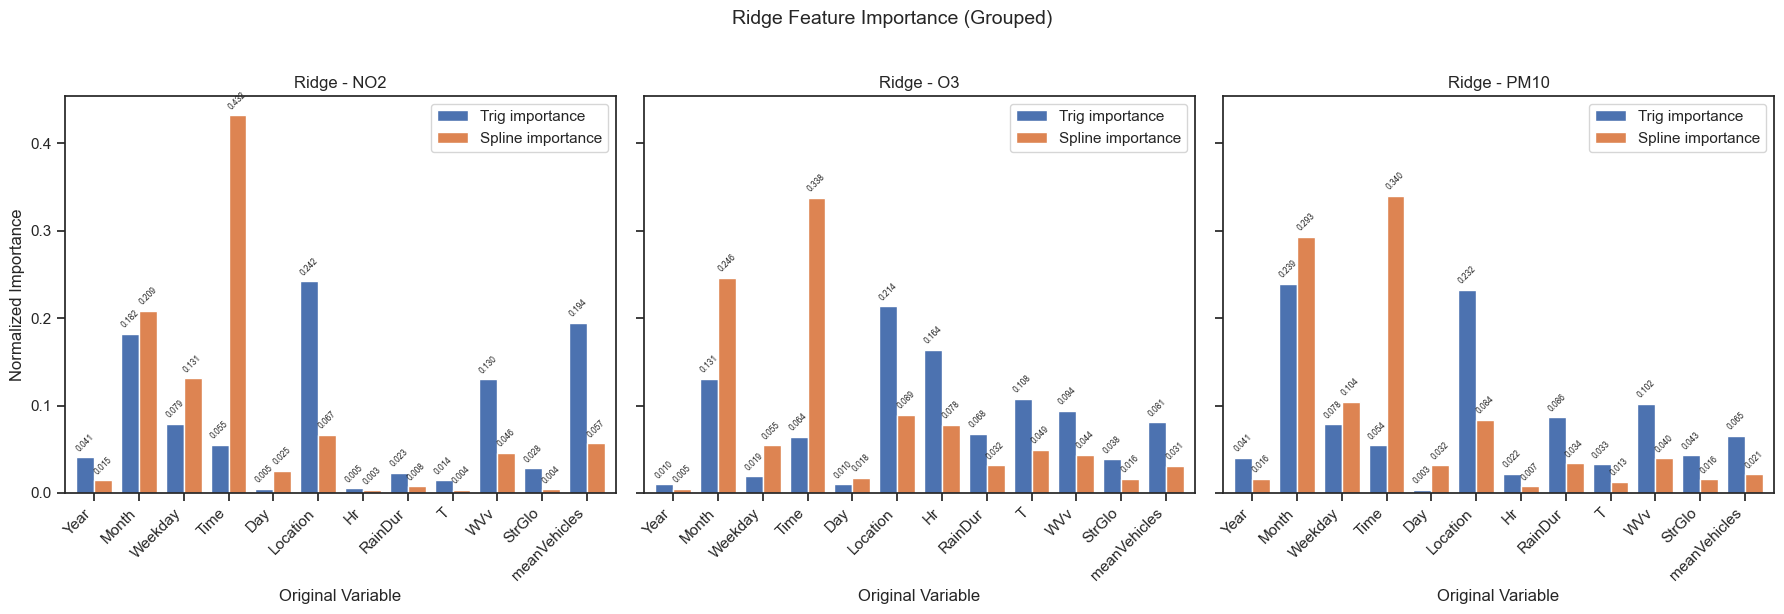

In [133]:
# Plot the grouped importance
plots = [
    {"tri_imp": g_imp_ridge_tri_NO2,  "spl_imp": g_imp_ridge_spl_NO2,  "feature_name": "NO2"},
    {"tri_imp": g_imp_ridge_tri_O3,   "spl_imp": g_imp_ridge_spl_O3,   "feature_name": "O3"},
    {"tri_imp": g_imp_ridge_tri_PM10, "spl_imp": g_imp_ridge_spl_PM10, "feature_name": "PM10"},
]

plot_grouped_importance_multi(
    plots,
    model_name="Ridge"
)

No weather or traffic feature is standing out as clearly not important for all 3 pollutants. For this reason, we keep all features in the dataset for the Lasso model

#### Model 4 - KNN Regression

In [134]:
# Train the models for the individual datasets
n_neighbors = 15

KNN_tri_NO2 = KNeighborsRegressor(n_neighbors, weights="uniform").fit(X_tri, y_NO2)
KNN_spl_NO2 = KNeighborsRegressor(n_neighbors, weights="uniform").fit(X_spl, y_NO2)

KNN_tri_O3 = KNeighborsRegressor(n_neighbors, weights="uniform").fit(X_tri, y_O3)
KNN_spl_O3 = KNeighborsRegressor(n_neighbors, weights="uniform").fit(X_spl, y_O3)

KNN_tri_PM10 = KNeighborsRegressor(n_neighbors, weights="uniform").fit(X_tri, y_PM10)
KNN_spl_PM10 = KNeighborsRegressor(n_neighbors, weights="uniform").fit(X_spl, y_PM10)

# Build grouped importance tables for all 6 models
g_imp_KNN_tri_NO2 = grouped_importance(KNN_tri_NO2, X_tri, y_NO2)
g_imp_KNN_spl_NO2 = grouped_importance(KNN_spl_NO2, X_spl, y_NO2)

g_imp_KNN_tri_O3 = grouped_importance(KNN_tri_O3, X_tri, y_O3)
g_imp_KNN_spl_O3 = grouped_importance(KNN_spl_O3, X_spl, y_O3)

g_imp_KNN_tri_PM10 = grouped_importance(KNN_tri_PM10, X_tri, y_PM10)
g_imp_KNN_spl_PM10 = grouped_importance(KNN_spl_PM10, X_spl, y_PM10)

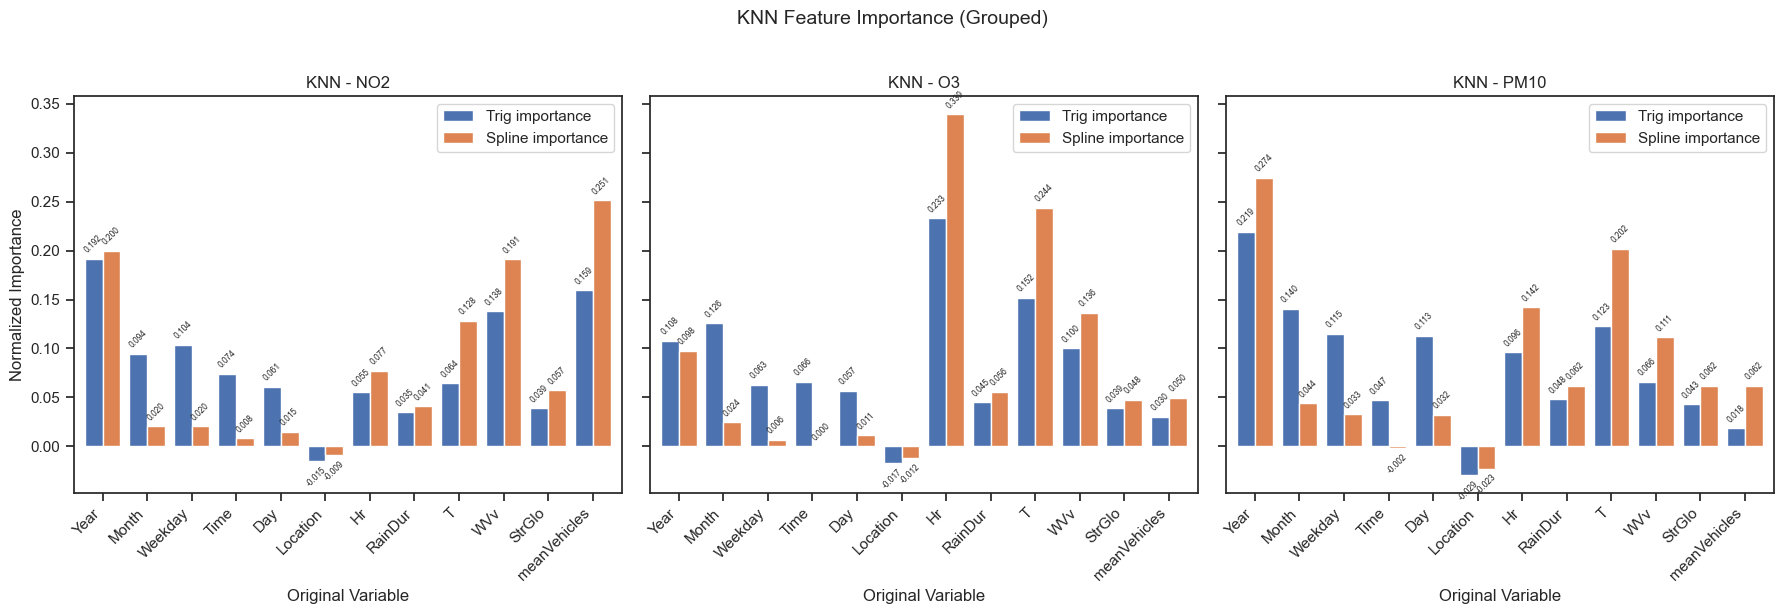

In [135]:
# Plot the grouped importance
plots = [
    {"tri_imp": g_imp_KNN_tri_NO2,  "spl_imp": g_imp_KNN_spl_NO2,  "feature_name": "NO2"},
    {"tri_imp": g_imp_KNN_tri_O3,   "spl_imp": g_imp_KNN_spl_O3,   "feature_name": "O3"},
    {"tri_imp": g_imp_KNN_tri_PM10, "spl_imp": g_imp_KNN_spl_PM10, "feature_name": "PM10"},
]

plot_grouped_importance_multi(
    plots,
    model_name="KNN"
)

Since Location feature shows negative value on the KNN Regressor performace, we will drop it from the X datasets for this model.

In [136]:
X_tri_KNN = X_tri.drop(["encoded__Location_Zch_Rosengartenstrasse", "encoded__Location_Zch_Schimmelstrasse", "encoded__Location_Zch_Stampfenbachstrasse"], axis="columns")
X_spl_KNN = X_spl.drop(["encoded__Location_Zch_Rosengartenstrasse", "encoded__Location_Zch_Schimmelstrasse", "encoded__Location_Zch_Stampfenbachstrasse"], axis="columns")

#### Model 5 - Random Forest Regressor

In [137]:
RF_tri_NO2 = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=5,
    max_samples=0.5,
    n_jobs=-1,
    random_state=42
).fit(X_tri, y_NO2)

RF_spl_NO2 = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=5,
    max_samples=0.5,
    n_jobs=-1,
    random_state=42
).fit(X_spl, y_NO2)

RF_tri_O3 = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=5,
    max_samples=0.5,
    n_jobs=-1,
    random_state=42
).fit(X_tri, y_O3)

RF_spl_O3 = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=5,
    max_samples=0.5,
    n_jobs=-1,
    random_state=42
).fit(X_spl, y_O3)

RF_tri_PM10 = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=5,
    max_samples=0.5,
    n_jobs=-1,
    random_state=42
).fit(X_tri, y_PM10)

RF_spl_PM10 = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=5,
    max_samples=0.5,
    n_jobs=-1,
    random_state=42
).fit(X_spl, y_PM10)

# Build grouped importance tables for all 6 models
g_imp_RF_tri_NO2 = grouped_importance(RF_tri_NO2, X_tri, y_NO2)
g_imp_RF_spl_NO2 = grouped_importance(RF_spl_NO2, X_spl, y_NO2)

g_imp_RF_tri_O3 = grouped_importance(RF_tri_O3, X_tri, y_O3)
g_imp_RF_spl_O3 = grouped_importance(RF_spl_O3, X_spl, y_O3)

g_imp_RF_tri_PM10 = grouped_importance(RF_tri_PM10, X_tri, y_PM10)
g_imp_RF_spl_PM10 = grouped_importance(RF_spl_PM10, X_spl, y_PM10)

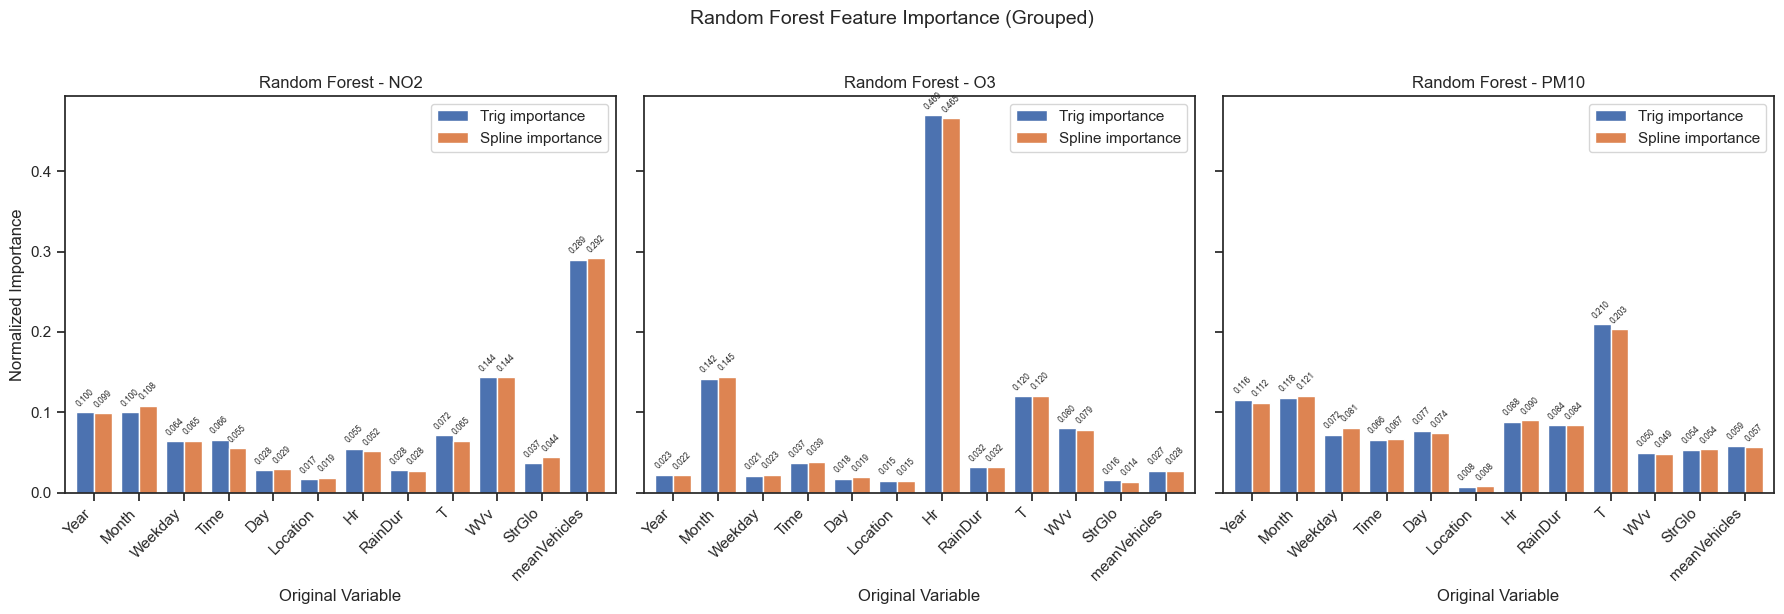

In [138]:
# Plot the grouped importance
plots = [
    {"tri_imp": g_imp_RF_tri_NO2,  "spl_imp": g_imp_RF_spl_NO2,  "feature_name": "NO2"},
    {"tri_imp": g_imp_RF_tri_O3,   "spl_imp": g_imp_RF_spl_O3,   "feature_name": "O3"},
    {"tri_imp": g_imp_RF_tri_PM10, "spl_imp": g_imp_RF_spl_PM10, "feature_name": "PM10"},
]

plot_grouped_importance_multi(
    plots,
    model_name="Random Forest"
)

The feature importance plot for NO2 and PM10 is comparable. Interestingly, the mean number of vehicles shows a lower influence on PM10 than for NO2 (for which it represents the highest influence). Year, Month and T (temperature) show the highest importance for PM10.
Hr (relative humidity), Month, T, and WVv (vector wind speed) have the highest influence on O3.
We will continue with all the features.

#### Model 7.1 - LDA 1D

In [139]:
n_components = 1
solver = "svd"

model_lda_tri = LDA(n_components=n_components, solver=solver).fit(X_tri_Loc, y_Location)
model_lda_spl = LDA(n_components=n_components, solver=solver).fit(X_spl_Loc, y_Location)

# Compute importance on the matching columns
imp_lda_coef_tri  = get_importance_lda(model_lda_tri,  X_tri_Loc.columns,  agg="l2")
imp_lda_coef_spl  = get_importance_lda(model_lda_spl,  X_spl_Loc.columns,  agg="l2")
imp_lda_load_tri  = get_importance_lda_loadings(model_lda_tri,  X_tri_Loc.columns,  agg="varweighted")
imp_lda_load_spl  = get_importance_lda_loadings(model_lda_spl,  X_spl_Loc.columns,  agg="varweighted")

# Group with matching X
g_imp_lda_coef_tri = grouped_from_series(imp_lda_coef_tri, X_tri_Loc)
g_imp_lda_load_tri = grouped_from_series(imp_lda_load_tri, X_tri_Loc)
g_imp_lda_coef_spl = grouped_from_series(imp_lda_coef_spl, X_spl_Loc)
g_imp_lda_load_spl = grouped_from_series(imp_lda_load_spl, X_spl_Loc)

In [140]:
# Plot the grouped importance
plot_grouped_importance(g_imp_lda_coef_tri, g_imp_lda_coef_spl, "Location")

TypeError: plot_grouped_importance() missing 1 required positional argument: 'feature_name'

#### Model 7.2 - LDA 2D

In [39]:
n_components = 2
solver = "svd"

model_lda_tri = LDA(n_components=n_components, solver=solver).fit(X_tri_Loc, y_Location)
model_lda_spl = LDA(n_components=n_components, solver=solver).fit(X_spl_Loc, y_Location)

# Compute importance on the matching columns
imp_lda_coef_tri  = get_importance_lda(model_lda_tri,  X_tri_Loc.columns,  agg="l2")
imp_lda_coef_spl  = get_importance_lda(model_lda_spl,  X_spl_Loc.columns,  agg="l2")
imp_lda_load_tri  = get_importance_lda_loadings(model_lda_tri,  X_tri_Loc.columns,  agg="varweighted")
imp_lda_load_spl  = get_importance_lda_loadings(model_lda_spl,  X_spl_Loc.columns,  agg="varweighted")

# Group with matching X
g_imp_lda_coef_tri = grouped_from_series(imp_lda_coef_tri, X_tri_Loc)
g_imp_lda_load_tri = grouped_from_series(imp_lda_load_tri, X_tri_Loc)

g_imp_lda_coef_spl = grouped_from_series(imp_lda_coef_spl, X_spl_Loc)
g_imp_lda_load_spl = grouped_from_series(imp_lda_load_spl, X_spl_Loc)

In [40]:
# Plot the grouped importance
plot_grouped_importance(g_imp_lda_coef_tri, g_imp_lda_coef_spl, "Location")

NameError: name 'plot_grouped_importance' is not defined

### 6. Hyperparameter Tuning

#### Model 2 - Lasso

In [53]:
# Find all hyperparams of the model
Lasso().get_params()

{'alpha': 1.0,
 'copy_X': True,
 'fit_intercept': True,
 'max_iter': 1000,
 'positive': False,
 'precompute': False,
 'random_state': None,
 'selection': 'cyclic',
 'tol': 0.0001,
 'warm_start': False}

Since Lasso model contains only few hyperparameters to tune, we will use Grid search

In [54]:
# Use a full grid over hyperparameters with a helper function
def tune_lasso(X, y, tss):
    """
    Run hyperparameter tuning for a single Lasso model using TimeSeriesSplit.
    """
    model = Lasso()

    param_grid = {
        "alpha": [0.001, 0.01, 0.1, 0.5, 1, 5, 10],
        "fit_intercept": [True, False],
        "max_iter": [5000]
    }

    search = GridSearchCV(
        estimator=model,
        param_grid=param_grid,
        cv=tss,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )

    search.fit(X, y)
    return search

# Compare tuning between the 6 models
tuned_lasso_tri_NO2 = tune_lasso(X_tri, y_NO2, tss)
tuned_lasso_spl_NO2 = tune_lasso(X_spl, y_NO2, tss)

tuned_lasso_tri_O3 = tune_lasso(X_tri, y_O3, tss)
tuned_lasso_spl_O3 = tune_lasso(X_spl, y_O3, tss)

tuned_lasso_tri_PM10 = tune_lasso(X_tri, y_PM10, tss)
tuned_lasso_spl_PM10 = tune_lasso(X_spl, y_PM10, tss)

# Put them in a list for easy print
tuned_lasso_models = [
    ("NO2 - Trig", tuned_lasso_tri_NO2),
    ("NO2 - Spline", tuned_lasso_spl_NO2),
    ("O3 - Trig", tuned_lasso_tri_O3),
    ("O3 - Spline", tuned_lasso_spl_O3),
    ("PM10 - Trig", tuned_lasso_tri_PM10),
    ("PM10 - Spline", tuned_lasso_spl_PM10)
]

# Summarize result
for name, model in tuned_lasso_models:
    print(f"Model: {name}")
    print(f"Best Score: {model.best_score_}")
    print(f"Best Hyperparameters: {model.best_params_}")
    print()

Model: NO2 - Trig
Best Score: -11.089663003547487
Best Hyperparameters: {'alpha': 0.1, 'fit_intercept': True, 'max_iter': 5000}

Model: NO2 - Spline
Best Score: -10.904957652670957
Best Hyperparameters: {'alpha': 0.01, 'fit_intercept': True, 'max_iter': 5000}

Model: O3 - Trig
Best Score: -17.453407661931585
Best Hyperparameters: {'alpha': 1, 'fit_intercept': True, 'max_iter': 5000}

Model: O3 - Spline
Best Score: -17.273447150222953
Best Hyperparameters: {'alpha': 0.5, 'fit_intercept': True, 'max_iter': 5000}

Model: PM10 - Trig
Best Score: -6.2093176156536245
Best Hyperparameters: {'alpha': 0.5, 'fit_intercept': True, 'max_iter': 5000}

Model: PM10 - Spline
Best Score: -6.180739875628598
Best Hyperparameters: {'alpha': 0.5, 'fit_intercept': True, 'max_iter': 5000}



#### Model 3 - Ridge

In [55]:
# Find all hyperparams of the model
Ridge().get_params()

{'alpha': 1.0,
 'copy_X': True,
 'fit_intercept': True,
 'max_iter': None,
 'positive': False,
 'random_state': None,
 'solver': 'auto',
 'tol': 0.0001}

Since Ridge model contains only few hyperparameters to tune, we will use Grid search

In [56]:
# Use a full grid over hyperparameters with a helper function
def tune_ridge(X, y, tss):
    """
    Run hyperparameter tuning for a single Ridge model using TimeSeriesSplit.
    """
    model = Ridge()

    param_grid = {
        "alpha": [0.001, 0.01, 0.1, 0.5, 1, 5, 10],
        "fit_intercept": [True, False],
        "max_iter": [5000]
    }

    search = GridSearchCV(
        estimator=model,
        param_grid=param_grid,
        cv=tss,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )

    search.fit(X, y)
    return search

# Compare tuning between the 6 models
tuned_ridge_tri_NO2 = tune_ridge(X_tri, y_NO2, tss)
tuned_ridge_spl_NO2 = tune_ridge(X_spl, y_NO2, tss)

tuned_ridge_tri_O3 = tune_ridge(X_tri, y_O3, tss)
tuned_ridge_spl_O3 = tune_ridge(X_spl, y_O3, tss)

tuned_ridge_tri_PM10 = tune_ridge(X_tri, y_PM10, tss)
tuned_ridge_spl_PM10 = tune_ridge(X_spl, y_PM10, tss)

# Put them in a list for easy print
tuned_ridge_models = [
    ("NO2 - Trig", tuned_ridge_tri_NO2),
    ("NO2 - Spline", tuned_ridge_spl_NO2),
    ("O3 - Trig", tuned_ridge_tri_O3),
    ("O3 - Spline", tuned_ridge_spl_O3),
    ("PM10 - Trig", tuned_ridge_tri_PM10),
    ("PM10 - Spline", tuned_ridge_spl_PM10)
]

# Summarize result
for name, model in tuned_ridge_models:
    print(f"Model: {name}")
    print(f"Best Score: {model.best_score_}")
    print(f"Best Hyperparameters: {model.best_params_}")
    print()

Model: NO2 - Trig
Best Score: -11.149539549911704
Best Hyperparameters: {'alpha': 10, 'fit_intercept': True, 'max_iter': 5000}

Model: NO2 - Spline
Best Score: -10.892325542540096
Best Hyperparameters: {'alpha': 10, 'fit_intercept': True, 'max_iter': 5000}

Model: O3 - Trig
Best Score: -19.101650713025492
Best Hyperparameters: {'alpha': 10, 'fit_intercept': True, 'max_iter': 5000}

Model: O3 - Spline
Best Score: -18.06332775751101
Best Hyperparameters: {'alpha': 1, 'fit_intercept': False, 'max_iter': 5000}

Model: PM10 - Trig
Best Score: -6.6744312045239145
Best Hyperparameters: {'alpha': 10, 'fit_intercept': False, 'max_iter': 5000}

Model: PM10 - Spline
Best Score: -6.451579553539455
Best Hyperparameters: {'alpha': 10, 'fit_intercept': False, 'max_iter': 5000}



#### Model 4 - KNN Regression

In [57]:
# Find all hyperparams of the model
KNeighborsRegressor().get_params()

{'algorithm': 'auto',
 'leaf_size': 30,
 'metric': 'minkowski',
 'metric_params': None,
 'n_jobs': None,
 'n_neighbors': 5,
 'p': 2,
 'weights': 'uniform'}

Since KNN Regression model contains more hyperparameters to tune, we will use Randomized search.

In [58]:
# Use a randomized grid over hyperparameters with a helper function
def tune_KNN(X, y, tss):
    """
    Run hyperparameter tuning for a single KNN Regression model using TimeSeriesSplit.
    """
    model = KNeighborsRegressor()

    param_grid = {
        "n_neighbors": [20, 25, 30, 35, 40, 100],
        "weights": ["uniform", "distance"],
        "metric": ["minkowski"],
        "p": [1, 2],
    }

    search = RandomizedSearchCV(
        estimator=model,
        param_distributions=param_grid,
        n_iter=20,
        cv=tss,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )

    search.fit(X, y)
    return search

# Compare tuning between the 6 models
tuned_KNN_tri_NO2 = tune_KNN(X_tri, y_NO2, tss)
tuned_KNN_spl_NO2 = tune_KNN(X_spl, y_NO2, tss)

tuned_KNN_tri_O3 = tune_KNN(X_tri, y_O3, tss)
tuned_KNN_spl_O3 = tune_KNN(X_spl, y_O3, tss)

tuned_KNN_tri_PM10 = tune_KNN(X_tri, y_PM10, tss)
tuned_KNN_spl_PM10 = tune_KNN(X_spl, y_PM10, tss)

# Put them in a list for easy print
tuned_KNN_models = [
    ("NO2 - Trig", tuned_KNN_tri_NO2),
    ("NO2 - Spline", tuned_KNN_spl_NO2),
    ("O3 - Trig", tuned_KNN_tri_O3),
    ("O3 - Spline", tuned_KNN_spl_O3),
    ("PM10 - Trig", tuned_KNN_tri_PM10),
    ("PM10 - Spline", tuned_KNN_spl_PM10)
]

# Summarize result
for name, model in tuned_KNN_models:
    print(f"Model: {name}")
    print(f"Best Score: {model.best_score_}")
    print(f"Best Hyperparameters: {model.best_params_}")
    print()

Model: NO2 - Trig
Best Score: -11.233086385503025
Best Hyperparameters: {'weights': 'uniform', 'p': 2, 'n_neighbors': 40, 'metric': 'minkowski'}

Model: NO2 - Spline
Best Score: -11.017791854482207
Best Hyperparameters: {'weights': 'distance', 'p': 2, 'n_neighbors': 30, 'metric': 'minkowski'}

Model: O3 - Trig
Best Score: -17.938460904496065
Best Hyperparameters: {'weights': 'distance', 'p': 2, 'n_neighbors': 100, 'metric': 'minkowski'}

Model: O3 - Spline
Best Score: -16.57801135752809
Best Hyperparameters: {'weights': 'distance', 'p': 2, 'n_neighbors': 100, 'metric': 'minkowski'}

Model: PM10 - Trig
Best Score: -6.211865515104399
Best Hyperparameters: {'weights': 'distance', 'p': 2, 'n_neighbors': 100, 'metric': 'minkowski'}

Model: PM10 - Spline
Best Score: -5.9965888801665965
Best Hyperparameters: {'weights': 'distance', 'p': 2, 'n_neighbors': 100, 'metric': 'minkowski'}



#### Model 5 - Random Forest Regressor

In [37]:
# Find all hyperparams of the model
RandomForestRegressor().get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': None,
 'max_features': 1.0,
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

Since Random Forest Regression model contains more hyperparameters to tune, we will use Randomized search.

In [40]:
# Use a randomized grid over hyperparameters with a helper function
def tune_RF(X, y, tss):
    """
    Run hyperparameter tuning for a single KNN Regression model using TimeSeriesSplit.
    """
    model = RandomForestRegressor()

    param_grid = {
        "max_depth": [10, 15, 20, None],
        "min_samples_leaf": randint(1, 21),
        "min_samples_split": randint(2, 41),
        "max_features": ["sqrt", 0.5, 0.8],
    }

    search = RandomizedSearchCV(
        estimator=model,
        param_distributions=param_grid,
        n_iter=20,
        cv=tss,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )

    search.fit(X, y)
    return search

# Compare tuning between the 6 models
tuned_RF_tri_NO2 = tune_RF(X_tri, y_NO2, tss)
tuned_RF_spl_NO2 = tune_RF(X_spl, y_NO2, tss)

tuned_RF_tri_O3 = tune_RF(X_tri, y_O3, tss)
tuned_RF_spl_O3 = tune_RF(X_spl, y_O3, tss)

tuned_RF_tri_PM10 = tune_RF(X_tri, y_PM10, tss)
tuned_RF_spl_PM10 = tune_RF(X_spl, y_PM10, tss)

# Put them in a list for easy print
tuned_RF_models = [
    ("NO2 - Trig", tuned_RF_tri_NO2),
    ("NO2 - Spline", tuned_RF_spl_NO2),
    ("O3 - Trig", tuned_RF_tri_O3),
    ("O3 - Spline", tuned_RF_spl_O3),
    ("PM10 - Trig", tuned_RF_tri_PM10),
    ("PM10 - Spline", tuned_RF_spl_PM10)
]

# Summarize result
for name, model in tuned_RF_models:
    print(f"Model: {name}")
    print(f"Best Score: {model.best_score_}")
    print(f"Best Hyperparameters: {model.best_params_}")
    print()

Model: NO2 - Trig
Best Score: -10.332892083179328
Best Hyperparameters: {'max_depth': 15, 'max_features': 0.5, 'min_samples_leaf': 7, 'min_samples_split': 23}

Model: NO2 - Spline
Best Score: -10.467642568058794
Best Hyperparameters: {'max_depth': 20, 'max_features': 0.5, 'min_samples_leaf': 9, 'min_samples_split': 5}

Model: O3 - Trig
Best Score: -16.71668365017711
Best Hyperparameters: {'max_depth': 10, 'max_features': 0.8, 'min_samples_leaf': 19, 'min_samples_split': 8}

Model: O3 - Spline
Best Score: -16.962868007722065
Best Hyperparameters: {'max_depth': 10, 'max_features': 0.8, 'min_samples_leaf': 18, 'min_samples_split': 40}

Model: PM10 - Trig
Best Score: -6.510041105823555
Best Hyperparameters: {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 12, 'min_samples_split': 16}

Model: PM10 - Spline
Best Score: -6.7442047183054274
Best Hyperparameters: {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 14, 'min_samples_split': 27}



#### Model 7 - LDA

### 6.2 Model evaluation 02

#### Model 2 - Lasso

In [260]:
# Evaluate models with tuned hyperparameters
# Put them in a list for easy print
evaluation_jobs = [
    ("NO2 - Trig", tuned_lasso_tri_NO2.best_estimator_, X_tri, y_NO2),
    ("NO2 - Spline", tuned_lasso_spl_NO2.best_estimator_, X_spl, y_NO2),
    ("O3 - Trig", tuned_lasso_tri_O3.best_estimator_, X_tri, y_O3),
    ("O3 - Spline", tuned_lasso_spl_O3.best_estimator_, X_spl, y_O3),
    ("PM10 - Trig", tuned_lasso_tri_PM10.best_estimator_, X_tri, y_PM10),
    ("PM10 - Spline", tuned_lasso_spl_PM10.best_estimator_, X_spl, y_PM10)
]

for name, model, X, y in evaluation_jobs:
    print(f"{name} RMSE is: ", end="")
    evaluate(model, X, y)

NO2 – Trig RMSE is: 11.09 ± 3.55
NO2 – Spline RMSE is: 10.90 ± 3.46
O3 – Trig RMSE is: 17.45 ± 4.46
O3 – Spline RMSE is: 17.27 ± 4.19
PM10 – Trig RMSE is: 6.21 ± 0.28
PM10 – Spline RMSE is: 6.18 ± 0.27


Using Lasso model, Spline encoding gives consistently, but only slightly better results. Out of the 3 pollutants, O3 is predicted with least accuracy and also highest variability.

#### Model 3 - Ridge

In [261]:
# Evaluate models with tuned hyperparameters
# Put them in a list for easy print
evaluation_jobs = [
    ("NO2 - Trig", tuned_ridge_tri_NO2.best_estimator_, X_tri, y_NO2),
    ("NO2 - Spline", tuned_ridge_spl_NO2.best_estimator_, X_spl, y_NO2),
    ("O3 - Trig", tuned_ridge_tri_O3.best_estimator_, X_tri, y_O3),
    ("O3 - Spline", tuned_ridge_spl_O3.best_estimator_, X_spl, y_O3),
    ("PM10 - Trig", tuned_ridge_tri_PM10.best_estimator_, X_tri, y_PM10),
    ("PM10 - Spline", tuned_ridge_spl_PM10.best_estimator_, X_spl, y_PM10)
]

for name, model, X, y in evaluation_jobs:
    print(f"{name} RMSE is: ", end="")
    evaluate(model, X, y)

NO2 – Trig RMSE is: 11.15 ± 3.46
NO2 – Spline RMSE is: 10.89 ± 3.44
O3 – Trig RMSE is: 19.10 ± 3.28
O3 – Spline RMSE is: 18.06 ± 3.29
PM10 – Trig RMSE is: 6.67 ± 1.33
PM10 – Spline RMSE is: 6.45 ± 1.00


Using Ridge model, Spline encoding gives consistently, but only slightly better results. Out of the 3 pollutants, O3 is predicted with least accuracy, while NO2 prediction shows the highest variability.

#### Model 4 - KNN Regression

In [304]:
# Evaluate models with tuned hyperparameters
# Put them in a list for easy print
evaluation_jobs = [
    ("NO2 - Trig", tuned_KNN_tri_NO2.best_estimator_, X_tri, y_NO2),
    ("NO2 - Spline", tuned_KNN_spl_NO2.best_estimator_, X_spl, y_NO2),
    ("O3 - Trig", tuned_KNN_tri_O3.best_estimator_, X_tri, y_O3),
    ("O3 - Spline", tuned_KNN_spl_O3.best_estimator_, X_spl, y_O3),
    ("PM10 - Trig", tuned_KNN_tri_PM10.best_estimator_, X_tri, y_PM10),
    ("PM10 - Spline", tuned_KNN_spl_PM10.best_estimator_, X_spl, y_PM10)
]

for name, model, X, y in evaluation_jobs:
    print(f"{name} RMSE is: ", end="")
    evaluate(model, X, y)

NO2 – Trig RMSE is: 11.20 ± 3.72
NO2 – Spline RMSE is: 11.02 ± 3.72
O3 – Trig RMSE is: 17.94 ± 4.65
O3 – Spline RMSE is: 16.58 ± 3.64
PM10 – Trig RMSE is: 6.21 ± 1.15
PM10 – Spline RMSE is: 6.00 ± 0.69


Using KNN Ridge Regression model, Spline encoding gives consistently, but only slightly better results. Out of the 3 pollutants, O3 is predicted with least accuracy and also shows the highest variability.

#### Model 5 - Random Forest Regressor

In [41]:
# Evaluate models with tuned hyperparameters
# Put them in a list for easy print
evaluation_jobs = [
    ("NO2 - Trig", tuned_RF_tri_NO2.best_estimator_, X_tri, y_NO2),
    ("NO2 - Spline", tuned_RF_spl_NO2.best_estimator_, X_spl, y_NO2),
    ("O3 - Trig", tuned_RF_tri_O3.best_estimator_, X_tri, y_O3),
    ("O3 - Spline", tuned_RF_spl_O3.best_estimator_, X_spl, y_O3),
    ("PM10 - Trig", tuned_RF_tri_PM10.best_estimator_, X_tri, y_PM10),
    ("PM10 - Spline", tuned_RF_spl_PM10.best_estimator_, X_spl, y_PM10)
]

for name, model, X, y in evaluation_jobs:
    print(f"{name} RMSE is: ", end="")
    evaluate(model, X, y)

NO2 - Trig RMSE is: 10.40 ± 3.59
NO2 - Spline RMSE is: 10.50 ± 3.64
O3 - Trig RMSE is: 16.91 ± 3.91
O3 - Spline RMSE is: 16.95 ± 4.19
PM10 - Trig RMSE is: 6.52 ± 1.25
PM10 - Spline RMSE is: 6.82 ± 1.44


dfgg

### 7. Model Evaluation Metrics

averaged across CV splits during model selection
reported on the final test year (2025)
- RMSE
- MAE

In [41]:
df_test_X = pd.read_csv("data/Datasets_MLready_pred_Location/X_test_transformed_Loc.csv")
df_test_y = pd.read_csv("data/Datasets_MLready_pred_Location/y_test_Loc.csv")


=== Fold 1 ===
Test size: 720 | Accuracy: 0.824 | Balanced Accuracy: 0.823
                     precision    recall  f1-score   support

 Rosengartenstrasse       0.93      0.75      0.83       239
    Schimmelstrasse       0.68      0.91      0.78       242
Stampfenbachstrasse       0.96      0.81      0.88       239

           accuracy                           0.82       720
          macro avg       0.85      0.82      0.83       720
       weighted avg       0.85      0.82      0.83       720


=== Fold 2 ===
Test size: 720 | Accuracy: 0.800 | Balanced Accuracy: 0.801
                     precision    recall  f1-score   support

 Rosengartenstrasse       0.92      0.65      0.76       241
    Schimmelstrasse       0.65      0.94      0.77       238
Stampfenbachstrasse       0.94      0.81      0.87       241

           accuracy                           0.80       720
          macro avg       0.84      0.80      0.80       720
       weighted avg       0.84      0.80      0.80

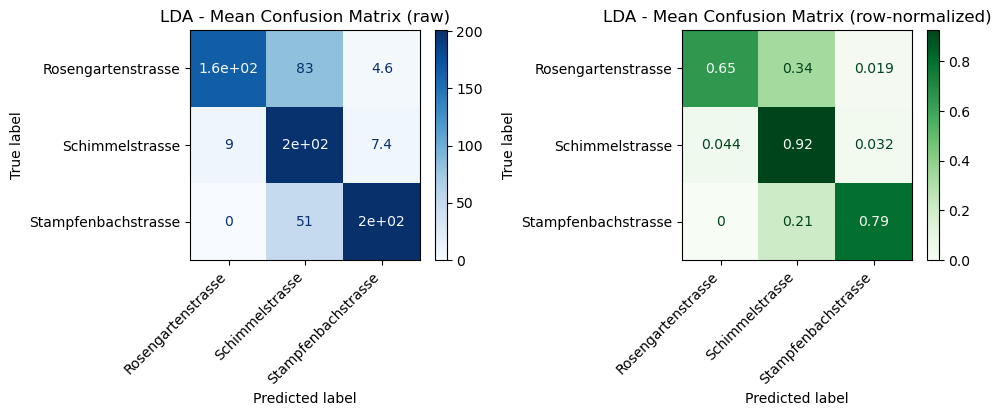

In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import TimeSeriesSplit
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, balanced_accuracy_score, classification_report
)
"""
# -----------------------------
# 1) Prepare labels & constants
# -----------------------------
loc_to_code = {
    'Zch_Rosengartenstrasse': 0,
    'Zch_Schimmelstrasse': 1,
    'Zch_Stampfenbachstrasse': 2
}
display_labels = ['Rosengartenstrasse', 'Schimmelstrasse', 'Stampfenbachstrasse']

# Ensure 1-D label Series, time-ordered X_all and y_all
y_codes = pd.Series(y_Location).map(loc_to_code).astype("int64")

# Feature columns: use all transformed columns (or a curated subset if you prefer)
feature_columns = df_train_X.columns.tolist()

# Your time series CV splitter
tss = TimeSeriesSplit(n_splits=5, gap=24*2, max_train_size=24 * 365, test_size=24 * 30)
"""
display_labels = ['Rosengartenstrasse', 'Schimmelstrasse', 'Stampfenbachstrasse']

feature_columns = df_train_X_Loc.columns.tolist()

# ------------------------------------------
# 2) Run CV folds: fit imputer + LDA per fold
# ------------------------------------------
fold_metrics = []
cms = []         # raw confusion matrices per fold
cms_norm = []    # normalized confusion matrices (row-normalized) per fold

for fold_idx, (train_idx, test_idx) in enumerate(tss.split(df_train_X_Loc, y_train_Location_codes), start=1):
    X_tr = df_train_X_Loc.iloc[train_idx][feature_columns]
    X_te = df_train_X_Loc.iloc[test_idx][feature_columns]
    y_tr = y_train_Location_codes.iloc[train_idx].values
    y_te = y_train_Location_codes.iloc[test_idx].values
    # Fit imputer on TRAIN only; transform train & test
    #imp = SimpleImputer(strategy="median")
    #X_tr_imp = imp.fit_transform(X_tr)
    #X_te_imp = imp.transform(X_te)

    # LDA (up to K-1 components; with 3 classes, 2 components available)
    n_classes = np.unique(y_train_Location_codes).size
    n_components = min(n_classes - 1, 2)
    lda = LDA(n_components=n_components, solver="svd")
    lda.fit(X_tr, y_tr)

    # Predict on TEST
    y_pred = lda.predict(X_te)

    # Confusion matrices
    cm = confusion_matrix(y_te, y_pred, labels=[0, 1, 2])
    cm_n = confusion_matrix(y_te, y_pred, labels=[0, 1, 2], normalize='true')

    cms.append(cm)
    cms_norm.append(cm_n)

    # Metrics
    acc = accuracy_score(y_te, y_pred)
    bacc = balanced_accuracy_score(y_te, y_pred)

    fold_metrics.append({
        "fold": fold_idx,
        "accuracy": acc,
        "balanced_accuracy": bacc,
        "n_test": len(test_idx)
    })

    # Optional: per-fold report (comment out if too verbose)
    print(f"\n=== Fold {fold_idx} ===")
    print(f"Test size: {len(test_idx)} | Accuracy: {acc:.3f} | Balanced Accuracy: {bacc:.3f}")
    print(classification_report(y_te, y_pred, target_names=display_labels))

# ---------------------------------
# 3) Aggregate metrics & matrices
# ---------------------------------
metrics_df = pd.DataFrame(fold_metrics)
print("\nCV metrics (per fold):")
print(metrics_df.round(3))

print("\nMean ± Std across folds:")
print(pd.DataFrame({
    "accuracy_mean":   [metrics_df["accuracy"].mean()],
    "accuracy_std":    [metrics_df["accuracy"].std(ddof=1)],
    "balanced_mean":   [metrics_df["balanced_accuracy"].mean()],
    "balanced_std":    [metrics_df["balanced_accuracy"].std(ddof=1)],
}).round(3))

# Aggregate confusion matrices by simple average (element-wise)
cm_mean     = np.mean(np.stack(cms, axis=0), axis=0)
cm_norm_mean = np.mean(np.stack(cms_norm, axis=0), axis=0)

# -------------------------------
# 4) Plot averaged confusion matrix
# -------------------------------
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

disp = ConfusionMatrixDisplay(confusion_matrix=cm_mean, display_labels=display_labels)
disp.plot(cmap="Blues", ax=ax[0], colorbar=True) #, xticks_rotation=45)
ax[0].set_title("LDA - Mean Confusion Matrix (raw)")

plt.sca(ax[0])
plt.xticks(rotation=45, ha="right")


disp_n = ConfusionMatrixDisplay(confusion_matrix=cm_norm_mean, display_labels=display_labels)
disp_n.plot(cmap="Greens", ax=ax[1], colorbar=True)
ax[1].set_title("LDA - Mean Confusion Matrix (row-normalized)")

plt.sca(ax[1])
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

### 8. Model Selection

#### Ensemble with Voting

In [74]:
best_Lasso_NO2 = tuned_lasso_spl_NO2.best_estimator_
best_Ridge_NO2 = tuned_ridge_spl_NO2.best_estimator_
best_KNN_NO2 = tuned_KNN_spl_NO2.best_estimator_
best_rf_NO2 = tuned_RF_tri_NO2.best_estimator_

best_Lasso_O3 = tuned_lasso_spl_O3.best_estimator_
best_Ridge_O3 = tuned_ridge_spl_O3.best_estimator_
best_KNN_O3 = tuned_KNN_spl_O3.best_estimator_
best_rf_O3 = tuned_RF_tri_O3.best_estimator_

best_Lasso_PM10 = tuned_lasso_spl_PM10.best_estimator_
best_Ridge_PM10 = tuned_ridge_spl_PM10.best_estimator_
best_KNN_PM10 = tuned_KNN_spl_PM10.best_estimator_
best_rf_PM10 = tuned_RF_tri_PM10.best_estimator_

In [78]:
voting_reg = VotingRegressor(
    estimators=[
        ("Ridge", best_Ridge_NO2),
        ("Lasso", best_Lasso_NO2),
        ("KNN", best_KNN_NO2),
        ("Random Forest", best_rf_NO2)
    ]
)

print("Ensemble, trigonometric encoding, NO2")
evaluate(voting_reg, X_tri, y_NO2)
print("Ensemble, spline encoding, NO2")
evaluate(voting_reg, X_spl, y_NO2)

print("Ensemble, trigonometric encoding, O3")
evaluate(voting_reg, X_tri, y_O3)
print("Ensemble, spline encoding, O3")
evaluate(voting_reg, X_spl, y_O3)

print("Ensemble, trigonometric encoding, PM10")
evaluate(voting_reg, X_tri, y_PM10)
print("Ensemble, spline encoding, PM10")
evaluate(voting_reg, X_spl, y_PM10)

Ensemble, trigonometric encoding, NO2
10.65 ± 3.63
Ensemble, spline encoding, NO2
10.56 ± 3.62
Ensemble, trigonometric encoding, O3
17.26 ± 3.96
Ensemble, spline encoding, O3
16.76 ± 3.79
Ensemble, trigonometric encoding, PM10
6.27 ± 0.93
Ensemble, spline encoding, PM10
6.15 ± 0.85


If the ensemble performs better than all single models
- error patterns are weakly correlated
- different models capture complementary structure
- the system is complex and multi-regime

In air pollution terms:
- traffic dominates at some times
- meteorology dominates at others
- linear models fail in some regimes, trees in others

If the ensemble is similar to the best model
- one model already captures most structure
- other models add little independent information
- the system is comparatively well-behaved
- In this case, the ensemble adds robustness, not insight.

If the ensemble is worse
- some models are systematically bad
- error correlation is high
- averaging dilutes strong signals

This often happens if:
- kNN struggles with high dimensionality
- linear models miss strong nonlinearities

“The ensemble performance was comparable to that of the best individual model, indicating that a single modelling approach already captured the dominant structure in the data.”

Compare all models (e.g. linear regression, random forest, ...)

- Mean CV RMSE
- Stability across folds (standard deviation)
- Interpretability
- Computational complexity

### 9. Final Training and Testing

With the best model only, not all of them

- The selected model is refit on all training data (2018–2024)
- Predictions are generated for 2025
- Final performance is reported on the test set

## Conclusion

## Use of Generative AI

- creating plots